# Data Mining – Données logistiques ERP (Meridian BioLogistics)

Analyse des 7 fichiers CSV de `data/logistics`.

Plan :
1. Chargement
2. Qualité des données
3. Nettoyage
4. Intégrité référentielle et jointures
5. Analyse exploratoire
6. Règles métier
7. Détection d'anomalies (Isolation Forest, LOF)
8. Clustering des partenaires (K-Means, CAH, ACP)
9. Règles d'association (Apriori)
10. Classification des expéditions à problème
11. Analyse temporelle
12. Score de risque, export et conclusions

## 0. Environnement

In [1]:
import re, warnings
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, classification_report, confusion_matrix,
                             roc_auc_score, ConfusionMatrixDisplay)
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.neighbors import LocalOutlierFactor
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
RANDOM_STATE = 42

# style des graphiques
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
sns.set_theme(style="whitegrid", palette=PALETTE)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "grid.color": "#e6e6e6", "lines.linewidth": 2, "axes.titleweight": "bold"})

# dossiers
DATA_DIR = Path("../data/logistics")
OUT_DIR = DATA_DIR / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Chargement

On charge tout en texte (`dtype=str`) pour pouvoir auditer les formats avant de convertir. Sinon une seule valeur comme `"14 kit"` peut faire mal typer toute une colonne.

In [2]:
FILES = ["erp_business_partners", "erp_facilities", "purchase_order_lines", "goods_receipts",
         "shipments", "inventory_month_end", "inventory_adjustments"]
raw = {name: pd.read_csv(DATA_DIR / f"{name}.csv", dtype=str, keep_default_na=True) for name in FILES}

overview = pd.DataFrame({
    "lignes": {k: v.shape[0] for k, v in raw.items()},
    "colonnes": {k: v.shape[1] for k, v in raw.items()},
    "cellules vides": {k: int(v.isna().sum().sum()) for k, v in raw.items()},
    "lignes dupliquées": {k: int(v.duplicated().sum()) for k, v in raw.items()},
})
overview

,lignes,colonnes,cellules vides,lignes dupliquées
erp_business_partners,80,11,15,0
erp_facilities,30,11,1,0
purchase_order_lines,651,16,3,1
goods_receipts,612,12,4,2
shipments,452,16,17,2
inventory_month_end,502,11,0,2
inventory_adjustments,140,11,221,0


Tables petites (30 à 651 lignes). On a 7 lignes dupliquées, 221 cellules vides dans les ajustements et 17 dans les expéditions.

In [3]:
for name, df in raw.items():
    print(f"\n=== {name} ===")
    display(df.head(3))


=== erp_business_partners ===


,partner_code,partner_name,partner_role,external_registration_number,billing_region,shipping_region,default_currency,payment_terms,partner_status,risk_class,onboarding_date
0,BP-30001,Marula Cold Store Cooperative,supplier_customer,REG-AVL-20012,Avelora Federation,Eastern Avelora Agricultural Cluster,AVL,NET45,active,review,2001-02-01
1,BP-30002,Blue Heron Monitoring Cooperative,customer,REG-KNT-20037,Kintara Republic,Kintara Karst Cluster,KRN,NET45,active,standard,2012-03-01
2,BP-30003,Orra Technical Services,supplier,REG-AVL-20022,Avelora Federation,Eastern Avelora Agricultural Cluster,AVL,PUBLIC30,active,review,2008-04-01



=== erp_facilities ===


,facility_code,facility_name,facility_category,operating_partner_code,street_address,region,latitude,longitude,opening_date,facility_status,storage_capabilities
0,FCL-1011,Meridian Valenne Headquarters,office,BP-30078,"Meridian Valenne Headquarters, Valenne Central...",Valenne Central District,47.24,7.58,2006-01-01,active,ambient
1,FCL-1024,Meridian Kintara Biological Aggregation Facility,warehouse,BP-30078,Meridian Kintara Biological Aggregation Facili...,Kintara Karst Cluster,4.74,112.28,1997-01-01,active,ambient;secure_cage;2-8C;frozen
2,FCL-1019,Meridian Avelora Transfer Annex,transfer_hub,BP-30078,"Meridian Avelora Transfer Annex, Eastern Avelo...",Eastern Avelora Agricultural Cluster,7.46,101.91,2003-01-01,active,ambient;secure_cage;2-8C;frozen



=== purchase_order_lines ===


,purchase_order_number,purchase_order_line,order_date,ordering_facility_code,supplier_partner_code,item_code,item_description,item_category,ordered_quantity,ordered_unit,unit_price,currency,requested_delivery_date,authorization_class,declared_cost_center,order_status
0,PO-2014-00001,1,2014-06-24,FCL-1007,BP-30078,ITM-MED-001,General clinical consumable case,medical_consumables,73,case,157.85,VLN,2014-07-08,restricted,Clinical Programmes,completed
1,PO-2015-00001,1,2015-01-22,FCL-1010,BP-30068,ITM-TRN-001,Regional refrigerated transport service,transport_service,1,service,3482.27,VLN,2015-02-01,ordinary,Clinical Services,completed
2,PO-2015-00002,1,2015-01-29,FCL-1030,BP-30066,ITM-COM-001,Secure communication service,communication_service,1,service,1292.19,KRN,2015-02-26,ordinary,General Operations,completed


... (4 outputs left out)


=== inventory_month_end ===


,facility_code,reporting_month,item_category,opening_stock,received_quantity,outgoing_quantity,documented_internal_use,documented_waste,closing_stock,unit,inventory_status
0,FCL-1024,2018-02-01,biological_sample,14.55 sealed_lot,5.46,0.00,0.49,0.22,16.24,sealed_lot,closed
1,FCL-1024,2018-03-01,biological_sample,16.24,5.00,0.00,1.94,0.65,0.55,sealed_lot,closed
2,FCL-1024,2018-05-01,biological_sample,0.55,0.00,0.00,0.00,0.36,0.17,sealed_lot,closed



=== inventory_adjustments ===


,adjustment_number,facility_code,adjustment_date,item_category,adjustment_quantity,unit,adjustment_reason,approved_by_role,related_receipt_number,related_shipment_number,adjustment_status
0,ADJ-2014-00001,FCL-1007,2014-07-18,medical_consumables,-1.58,case,specialist programme issue,clinical stores manager,NaN,NaN,posted
1,ADJ-2015-00002,FCL-1007,2015-09-10,medical_consumables,-2.7,case,specialist programme issue,specialist programme administrator,NaN,NaN,posted
2,ADJ-2015-00003,FCL-1024,2015-10-30,monitoring_equipment,3.68,kit,late receipt posting,warehouse manager,RCV-2022-00361,NaN,posted


## 2. Qualité des données

On mesure les défauts avant de corriger quoi que ce soit, pour pouvoir documenter le nettoyage.

### 2.1 Valeurs manquantes

In [4]:
missing = (pd.concat({k: v.isna().sum() for k, v in raw.items()})
             .rename("nb_manquants").reset_index()
             .rename(columns={"level_0": "table", "level_1": "colonne"}))
missing = missing[missing.nb_manquants > 0]
missing["pct"] = missing.apply(lambda r: 100 * r.nb_manquants / len(raw[r.table]), axis=1).round(1)
missing.sort_values("pct", ascending=False)

,table,colonne,nb_manquants,pct
85,inventory_adjustments,related_receipt_number,117,83.6
86,inventory_adjustments,related_shipment_number,103,73.6
3,erp_business_partners,external_registration_number,14,17.5
53,shipments,arrival_time,17,3.8
21,erp_facilities,storage_capabilities,1,3.3
4,erp_business_partners,billing_region,1,1.2
47,goods_receipts,inspection_status,4,0.7
84,inventory_adjustments,approved_by_role,1,0.7
36,purchase_order_lines,declared_cost_center,3,0.5


- `related_receipt_number` / `related_shipment_number` vides à 74–84 % : normal, un ajustement n'a pas toujours de pièce liée. On s'en resert au §6.3.
- 14 partenaires (17,5 %) sans numéro d'enregistrement.
- 17 expéditions sans date d'arrivée : à vérifier que ce sont les `in_transit` (§4).
- Quelques vides sur des champs de contrôle (centre de coût, approbateur, statut d'inspection).

### 2.2 Colonnes numériques mal formées

In [5]:
NUMERIC_COLS = {
    "purchase_order_lines": ["ordered_quantity", "unit_price"],
    "goods_receipts": ["received_quantity"],
    "shipments": ["declared_quantity"],
    "inventory_month_end": ["opening_stock", "received_quantity", "outgoing_quantity",
                            "documented_internal_use", "documented_waste", "closing_stock"],
    "inventory_adjustments": ["adjustment_quantity"],
    "erp_facilities": ["latitude", "longitude"],
}
STRICT_NUM = re.compile(r"^-?\d+(\.\d+)?$")

def classify_bad_number(v):
    if re.match(r"^-?\d+,\d+$", v): return "virgule décimale"
    if re.match(r"^-?[\d.,]+\s+[A-Za-z_]+$", v): return "unité collée au nombre"
    return "autre"

rows = []
for t, cols in NUMERIC_COLS.items():
    for c in cols:
        s = raw[t][c].dropna().str.strip()
        bad = s[~s.str.match(STRICT_NUM)]
        for v in bad:
            rows.append((t, c, classify_bad_number(v), v))
bad_numbers = pd.DataFrame(rows, columns=["table", "colonne", "type_defaut", "exemple"])
print(f"{len(bad_numbers)} valeurs numériques mal formées")
bad_numbers.groupby(["table", "colonne", "type_defaut"]).agg(n=("exemple", "size"), exemple=("exemple", "first"))

45 valeurs numériques mal formées


n           exemple
table                 colonne             type_defaut                                
goods_receipts        received_quantity   unité collée au nombre  8            14 kit
                                          virgule décimale        6             56,41
inventory_adjustments adjustment_quantity unité collée au nombre  1         -2.9 case
inventory_month_end   closing_stock       unité collée au nombre  4   0.92 sealed_lot
                      documented_waste    virgule décimale        2              1,45
                      opening_stock       unité collée au nombre  4  14.55 sealed_lot
                      outgoing_quantity   virgule décimale        3             17,00
                      received_quantity   virgule décimale        3              1,04
purchase_order_lines  ordered_quantity    unité collée au nombre  8           88 case
                      unit_price          virgule décimale        6           2469,48

45 valeurs mal formées, deux cas : virgule décimale (`56,41`) et unité collée (`14 kit`). Les deux se corrigent facilement. On vérifie au §3 que l'unité collée correspond bien à la colonne d'unité.

### 2.3 Formats de dates

On liste les formats présents pour ne pas inverser jour et mois.

In [6]:
DATE_COLS = {
    "purchase_order_lines": ["order_date", "requested_delivery_date"],
    "goods_receipts": ["receipt_date"],
    "shipments": ["dispatch_time", "arrival_time"],
    "inventory_adjustments": ["adjustment_date"],
    "inventory_month_end": ["reporting_month"],
    "erp_business_partners": ["onboarding_date"],
    "erp_facilities": ["opening_date"],
}
def date_pattern(v):
    v = re.sub(r"[ T]\d{2}:\d{2}(:\d{2})?$", "", v)          # on ignore l'heure
    return re.sub(r"[A-Za-z]{3}", "Mon", re.sub(r"\d", "9", v))

pat = []
for t, cols in DATE_COLS.items():
    for c in cols:
        vc = raw[t][c].dropna().map(date_pattern).value_counts()
        for p, n in vc.items():
            pat.append((t, c, p, n))
date_patterns = pd.DataFrame(pat, columns=["table", "colonne", "motif", "n"])
date_patterns.pivot_table(index=["table", "colonne"], columns="motif", values="n", fill_value=0)

motif                                          99-Mon-9999  99/99/9999  9999-99-99  9999/99/99
table                 colonne                                                                 
erp_business_partners onboarding_date                  0.0         1.0        79.0         0.0
erp_facilities        opening_date                     0.0         0.0        30.0         0.0
goods_receipts        receipt_date                     0.0         2.0       607.0         3.0
inventory_adjustments adjustment_date                  1.0         1.0       138.0         0.0
inventory_month_end   reporting_month                  0.0         0.0       502.0         0.0
purchase_order_lines  order_date                       1.0         0.0       648.0         2.0
                      requested_delivery_date          1.0         1.0       648.0         1.0
shipments             arrival_time                     2.0         1.0       432.0         0.0
                      dispatch_time                    1.0         0.0       449.0         2.0

4 formats : `aaaa-mm-jj` (la grande majorité), `aaaa/mm/jj`, `jj/mm/aaaa` et `jj-Mon-aaaa`. Une vingtaine de dates seulement ne sont pas en ISO. Le format `xx/xx/aaaa` est ambigu, on le teste ci-dessous.

In [7]:
# jj/mm ou mm/jj ? si le 1er nombre > 12, c'est le jour
slash = pd.concat([raw[t][c] for t, cs in DATE_COLS.items() for c in cs]).dropna()
slash = slash[slash.str.match(r"^\d{2}/\d{2}/\d{4}")]
first = slash.str[:2].astype(int); second = slash.str[3:5].astype(int)
print("Dates jj/mm/aaaa :", len(slash), "| 1er nombre > 12 :", (first > 12).sum(), "| 2e nombre > 12 :", (second > 12).sum())

Dates jj/mm/aaaa : 6 | 1er nombre > 12 : 3 | 2e nombre > 12 : 0


Le premier nombre dépasse parfois 12, jamais le second : c'est donc du `jj/mm/aaaa`.

### 2.4 Modalités (casse, espaces)

On compare le nombre de modalités avant et après passage en minuscules et suppression des espaces.

In [8]:
def norm_txt(s):
    return s.str.strip().str.replace(r"\s+", " ", regex=True).str.lower()

rows = []
for t, df in raw.items():
    for c in df.columns:
        n_raw = df[c].nunique()
        if 1 < n_raw <= 40:
            n_norm = norm_txt(df[c].dropna()).nunique()
            if n_norm < n_raw:
                variants = (df[c].dropna().groupby(norm_txt(df[c].dropna())).unique()
                              .loc[lambda s: s.map(len) > 1].map(list).to_dict())
                rows.append((t, c, n_raw, n_norm, variants))
pd.DataFrame(rows, columns=["table", "colonne", "modalités brutes", "modalités normalisées", "variantes"])

,table,colonne,modalités brutes,modalités normalisées,variantes
0,erp_business_partners,partner_role,6,5,"{'supplier': ['supplier', 'Supplier']}"
1,purchase_order_lines,item_category,23,18,"{'agricultural_equipment': ['agricultural_equipment', 'AGRICULTURAL_EQUIPMENT'], 'laboratory_material': ['laboratory_material', 'LABORATORY_MATERIAL'], 'medical_consumables': ['medical_consumables', 'MEDICAL_CONSUMABLES'], 'monitoring_equipment': ['monitoring_equipment', 'MONITORING_EQUIPMENT'], 'protective_equipment': ['protective_equipment', 'PROTECTIVE_EQUIPMENT']}"
2,goods_receipts,receipt_status,3,2,"{'posted': ['posted', 'POSTED']}"
3,shipments,temperature_control_class,6,3,"{'2-8c': ['2-8C', '2-8c'], 'ambient': ['ambient', 'Ambient'], 'frozen': ['frozen', 'FROZEN']}"
4,shipments,declared_purpose,12,8,"{'customer distribution': ['customer distribution', ' customer distribution '], 'field programme support': ['field programme support', ' field programme support '], 'laboratory delivery': ['laboratory delivery', ' laboratory delivery '], 'scheduled stock transfer': ['scheduled stock transfer', ' scheduled stock transfer ']}"
5,shipments,shipment_status,7,4,"{'delayed': ['delayed', 'DELAYED'], 'delivered': ['delivered', 'Delivered', 'DELIVERED']}"
6,inventory_month_end,inventory_status,5,3,"{'closed': ['closed', 'CLOSED'], 'provisional': ['provisional', 'PROVISIONAL']}"
7,inventory_adjustments,adjustment_reason,12,10,"{'transfer posting correction': ['transfer posting correction', 'Transfer Posting Correction', 'TRANSFER POSTING CORRECTION']}"


8 colonnes concernées. Par exemple `shipment_status` passe de 7 à 4 modalités, `temperature_control_class` de 6 à 3, `item_category` de 23 à 18 et `declared_purpose` de 12 à 8.

### 2.5 Doublons de clés

On regarde aussi les doublons sur les clés métier, pas seulement les lignes identiques.

In [9]:
KEYS = {"purchase_order_lines": ["purchase_order_number", "purchase_order_line"],
        "goods_receipts": ["receipt_number"], "shipments": ["shipment_number", "shipment_leg"],
        "inventory_adjustments": ["adjustment_number"], "erp_business_partners": ["partner_code"],
        "erp_facilities": ["facility_code"],
        "inventory_month_end": ["facility_code", "reporting_month", "item_category"]}
for t, k in KEYS.items():
    df = raw[t]
    dup_key = df.duplicated(k, keep=False)
    dup_full = df.duplicated(keep=False)
    print(f"{t:25s} clés dupliquées : {dup_key.sum():3d} lignes | dont copies exactes : {(dup_key & dup_full).sum():3d}")

purchase_order_lines      clés dupliquées :   2 lignes | dont copies exactes :   2
goods_receipts            clés dupliquées :   4 lignes | dont copies exactes :   4
shipments                 clés dupliquées :   4 lignes | dont copies exactes :   4
inventory_adjustments     clés dupliquées :   0 lignes | dont copies exactes :   0
erp_business_partners     clés dupliquées :   0 lignes | dont copies exactes :   0
erp_facilities            clés dupliquées :   0 lignes | dont copies exactes :   0
inventory_month_end       clés dupliquées :   4 lignes | dont copies exactes :   4


Tous les doublons de clés sont des copies exactes, on peut les supprimer.

### 2.6 Partenaires : noms et régions

Certains noms ont des espaces en trop, et `shipping_region` contient parfois un pays au lieu d'un district.

In [10]:
bp = raw["erp_business_partners"]
print("Noms avec espaces parasites :", (bp.partner_name != bp.partner_name.str.strip().str.replace(r"\s+", " ", regex=True)).sum())
countries = set(bp.billing_region.dropna())
print("shipping_region renseigné au niveau pays :", bp.shipping_region.isin(countries).sum(), "partenaires")
print("Partenaires sans numéro d'enregistrement :", bp.external_registration_number.isna().sum())
bp[bp.shipping_region.isin(countries) | bp.external_registration_number.isna()][
    ["partner_code", "partner_name", "partner_role", "billing_region", "shipping_region",
     "external_registration_number", "risk_class"]].head(12)

Noms avec espaces parasites : 1
shipping_region renseigné au niveau pays : 14 partenaires
Partenaires sans numéro d'enregistrement : 14


,partner_code,partner_name,partner_role,billing_region,shipping_region,external_registration_number,risk_class
4,BP-30005,Warden Medical Ventures,service_partner,Valenne Republic,Valenne Republic,REG-VLN-01016,standard
5,BP-30006,Avelora Food Standards Office,customer,Avelora Federation,Eastern Avelora Agricultural Cluster,NaN,standard
9,BP-30010,Tembara Coastal Administration,customer,Tembara Commonwealth,Tembara Commonwealth,NaN,low
12,BP-30013,Vann Maritime Advisory,service_partner,Nordhaven Union,Nordhaven Union,REG-NDH-01015,standard
15,BP-30016,Kintara Cave and Pollinator Authority,customer,Kintara Republic,Kintara Karst Cluster,NaN,low
18,BP-30019,Orison Medical Audit Board,customer,Valenne Republic,Valenne Central District,NaN,review
21,BP-30022,Varlan Natural History Circle,customer,Kintara Republic,Kintara Republic,REG-KNT-01018,low
26,BP-30027,Kintara Emergency Response Office,customer,Kintara Republic,Kintara Karst Cluster,NaN,low
34,BP-30035,Ardena Capital Union,service_partner,Valenne Republic,Valenne Republic,REG-VLN-01023,elevated
35,BP-30036,Office of the Kintara Chancellor,customer,Kintara Republic,Kintara Republic,NaN,low


14 partenaires ont un pays dans `shipping_region`. On ne peut pas retrouver le district, donc on ajoute juste un indicateur `shipping_region_is_country`. Parmi les partenaires sans numéro d'enregistrement il y a des administrations (normal) mais aussi des entreprises privées.

## 3. Nettoyage

On corrige : séparateur décimal, unités collées, casse, espaces, dates, doublons. L'unité extraite est gardée dans `*_unit_in_value` pour la comparer à la colonne d'unité.

In [11]:
def parse_number(series):
    # '1,04' -> 1.04, '14 kit' -> 14 (+ unité extraite)
    s = series.astype("string").str.strip()
    unit_in_value = s.str.extract(r"^[-\d.,]+\s+([A-Za-z_]+)$")[0]
    num = s.str.replace(r"\s+[A-Za-z_]+$", "", regex=True).str.replace(",", ".", regex=False)
    return pd.to_numeric(num, errors="coerce").astype(float), unit_in_value

DATE_FORMATS = ["%Y-%m-%dT%H:%M:%S", "%Y-%m-%d %H:%M:%S", "%Y-%m-%d", "%Y/%m/%d %H:%M:%S", "%Y/%m/%d",
                "%d/%m/%Y %H:%M:%S", "%d/%m/%Y", "%d-%b-%Y %H:%M:%S", "%d-%b-%Y"]
def parse_date(series):
    s = series.astype("string").str.strip()
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    for fmt in DATE_FORMATS:
        todo = out.isna() & s.notna()
        if not todo.any(): break
        out[todo] = pd.to_datetime(s[todo], format=fmt, errors="coerce")
    unparsed = s.notna() & out.isna()
    if unparsed.any(): print("  ⚠ dates non reconnues :", s[unparsed].unique()[:5])
    return out

def clean_cat(series):
    return series.astype("string").str.strip().str.replace(r"\s+", " ", regex=True).str.lower()

clean, log = {}, []
for t, df in raw.items():
    df = df.copy()
    n0 = len(df)
    df = df.drop_duplicates()
    log.append((t, "copies exactes supprimées", n0 - len(df)))
    for c in NUMERIC_COLS.get(t, []):
        df[c], u = parse_number(df[c])
        if u.notna().any():
            df[c + "_unit_in_value"] = u
    for c in DATE_COLS.get(t, []):
        df[c] = parse_date(df[c])
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_datetime64_any_dtype(df[c]) \
           and not c.endswith(("_number", "_code", "_line", "_leg")) \
           and c not in ("partner_name", "facility_name", "street_address", "item_description", "batch_reference"):
            if df[c].nunique() <= 40:
                df[c] = clean_cat(df[c])
    clean[t] = df

# corrections au cas par cas
bp = clean["erp_business_partners"]
bp["partner_name"] = bp.partner_name.str.strip().str.replace(r"\s+", " ", regex=True)
countries = set(bp.billing_region.dropna())
bp["shipping_region_is_country"] = bp.shipping_region.isin(countries)
for t, c in [("purchase_order_lines", "currency"), ("erp_business_partners", "default_currency")]:
    clean[t][c] = clean[t][c].str.upper()
sh = clean["shipments"]
sh["temperature_control_class"] = sh.temperature_control_class.str.replace("2-8c", "2-8C")
clean["erp_facilities"]["storage_capabilities"] = clean["erp_facilities"].storage_capabilities.str.replace("2-8c", "2-8C")
for c in ["latitude", "longitude"]:
    clean["erp_facilities"][c] = clean["erp_facilities"][c].astype(float)

# unité collée vs colonne d'unité
UNIT_COL = {"purchase_order_lines": "ordered_unit", "goods_receipts": "received_unit", "inventory_month_end": "unit",
            "inventory_adjustments": "unit"}
for t, ucol in UNIT_COL.items():
    for c in [c for c in clean[t].columns if c.endswith("_unit_in_value")]:
        m = clean[t][c].notna()
        print(f"{t}.{c}: {m.sum()} valeurs, unité discordante : {(clean[t].loc[m, c] != clean[t].loc[m, ucol]).sum()}")

pd.DataFrame(log, columns=["table", "opération", "n"]).query("n > 0")

purchase_order_lines.ordered_quantity_unit_in_value: 8 valeurs, unité discordante : 0
goods_receipts.received_quantity_unit_in_value: 8 valeurs, unité discordante : 0
inventory_month_end.opening_stock_unit_in_value: 4 valeurs, unité discordante : 0
inventory_month_end.closing_stock_unit_in_value: 4 valeurs, unité discordante : 0
inventory_adjustments.adjustment_quantity_unit_in_value: 1 valeurs, unité discordante : 0


,table,opération,n
2,purchase_order_lines,copies exactes supprimées,1
3,goods_receipts,copies exactes supprimées,2
4,shipments,copies exactes supprimées,2
5,inventory_month_end,copies exactes supprimées,2


7 doublons supprimés, tout est converti, et aucune unité collée ne contredit la colonne d'unité.

In [12]:
# vérif : aucune valeur perdue à la conversion
for t, cols in NUMERIC_COLS.items():
    for c in cols:
        assert clean[t][c].isna().sum() == raw[t][c].isna().sum(), (t, c)
print("Statuts d'expédition :", sorted(clean["shipments"].shipment_status.unique()))
print("Classes de température :", sorted(clean["shipments"].temperature_control_class.unique()))
print("Statuts de réception :", sorted(clean["goods_receipts"].receipt_status.unique()))
print("Catégories (commandes) :", clean["purchase_order_lines"].item_category.nunique())

Statuts d'expédition : ['delayed', 'delivered', 'in_transit', 'returned']
Classes de température : ['2-8C', 'ambient', 'frozen']
Statuts de réception : ['posted', 'quality_hold']
Catégories (commandes) : 18


Modalités propres (4 statuts, 3 classes de température, 18 catégories) et aucune valeur perdue.

## 4. Intégrité référentielle et jointures

On vérifie que tous les codes référencés existent, puis on construit deux tables : commandes + réceptions, et expéditions enrichies avec les infos des sites.

In [13]:
P, F = set(clean["erp_business_partners"].partner_code), set(clean["erp_facilities"].facility_code)
po, gr, sh = clean["purchase_order_lines"], clean["goods_receipts"], clean["shipments"]
adj, inv = clean["inventory_adjustments"], clean["inventory_month_end"]
checks = {
    "PO.supplier → partenaires": set(po.supplier_partner_code) - P,
    "PO.site → sites": set(po.ordering_facility_code) - F,
    "GR.commande → PO": set(gr.purchase_order_number) - set(po.purchase_order_number),
    "GR.site → sites": set(gr.receiving_facility_code) - F,
    "SHP.expéditeur/destinataire/transporteur → partenaires": set(sh.sender_partner_code) | set(sh.receiver_partner_code) | set(sh.carrier_partner_code) - P,
    "SHP.origine/destination → sites": (set(sh.origin_facility_code) | set(sh.destination_facility_code)) - F,
    "ADJ.réception liée → GR": set(adj.related_receipt_number.dropna()) - set(gr.receipt_number),
    "ADJ.expédition liée → SHP": set(adj.related_shipment_number.dropna()) - set(sh.shipment_number),
}
checks["SHP.expéditeur/destinataire/transporteur → partenaires"] = (set(sh.sender_partner_code) | set(sh.receiver_partner_code) | set(sh.carrier_partner_code)) - P
pd.Series({k: len(v) for k, v in checks.items()}, name="codes orphelins").to_frame()

,codes orphelins
PO.supplier → partenaires,0
PO.site → sites,0
GR.commande → PO,0
GR.site → sites,0
SHP.expéditeur/destinataire/transporteur → partenaires,0
SHP.origine/destination → sites,0
ADJ.réception liée → GR,0
ADJ.expédition liée → SHP,0


Aucun code orphelin, les jointures ne perdent pas de lignes.

In [14]:
# rôle ERP des transporteurs et fournisseurs utilisés
roles = clean["erp_business_partners"].set_index("partner_code").partner_role
carrier_roles = roles.reindex(sh.carrier_partner_code.unique()).value_counts()
supplier_roles = roles.reindex(po.supplier_partner_code.unique()).value_counts()
pd.concat({"rôle des transporteurs utilisés": carrier_roles, "rôle des fournisseurs de commandes": supplier_roles}, axis=1).fillna(0).astype(int)

,rôle des transporteurs utilisés,rôle des fournisseurs de commandes
partner_role,,
carrier,9,9
customer,0,22
service_partner,0,18
supplier,0,14
supplier_customer,0,6


Les 9 transporteurs ont bien le rôle `carrier`. Par contre des commandes sont passées à des partenaires de tous les rôles, dont 22 `customer`. Le rôle ERP n'est pas très fiable.

In [15]:
# commandes + réceptions
po_gr = po.merge(gr, on=["purchase_order_number", "purchase_order_line"], how="left", suffixes=("_po", "_gr"))
po_gr["lead_time_days"] = (po_gr.receipt_date - po_gr.order_date).dt.days
po_gr["delay_vs_requested_days"] = (po_gr.receipt_date - po_gr.requested_delivery_date).dt.days
po_gr["qty_gap"] = po_gr.received_quantity - po_gr.ordered_quantity
po_gr["qty_gap_pct"] = 100 * po_gr.qty_gap / po_gr.ordered_quantity
po_gr["unit_mismatch"] = po_gr.received_unit.notna() & (po_gr.received_unit != po_gr.ordered_unit)
po_gr["supplier_mismatch"] = po_gr.supplier_partner_code_gr.notna() & (po_gr.supplier_partner_code_po != po_gr.supplier_partner_code_gr)
po_gr["facility_mismatch"] = po_gr.receiving_facility_code.notna() & (po_gr.ordering_facility_code != po_gr.receiving_facility_code)
po_gr["line_amount"] = po_gr.ordered_quantity * po_gr.unit_price
po_gr["year"] = po_gr.order_date.dt.year
print("Commandes sans réception :", po_gr.receipt_number.isna().sum(), "→ statuts :", po_gr[po_gr.receipt_number.isna()].order_status.value_counts().to_dict())

# expéditions + infos sites
fac = clean["erp_facilities"].set_index("facility_code")
sh["transit_hours"] = (sh.arrival_time - sh.dispatch_time).dt.total_seconds() / 3600
for side in ["origin", "destination"]:
    sh[f"{side}_category"] = sh[f"{side}_facility_code"].map(fac.facility_category)
    sh[f"{side}_region"] = sh[f"{side}_facility_code"].map(fac.region)
    sh[f"{side}_caps"] = sh[f"{side}_facility_code"].map(fac.storage_capabilities).fillna("")
sh["same_region"] = sh.origin_region == sh.destination_region
# distance haversine entre sites
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))
sh["distance_km"] = haversine(sh.origin_facility_code.map(fac.latitude), sh.origin_facility_code.map(fac.longitude),
                              sh.destination_facility_code.map(fac.latitude), sh.destination_facility_code.map(fac.longitude))
sh["year"] = sh.dispatch_time.dt.year
sh[["shipment_number", "origin_facility_code", "destination_facility_code", "distance_km", "transit_hours", "shipment_status"]].head()

Commandes sans réception : 40 → statuts : {'delayed': 18, 'pending': 14, 'cancelled': 8}


,shipment_number,origin_facility_code,destination_facility_code,distance_km,transit_hours,shipment_status
0,SHP-2014-00001,FCL-1011,FCL-1007,9711.265639,18.0,delivered
1,SHP-2015-00001,FCL-1009,FCL-1013,23.213111,77.0,returned
2,SHP-2015-00002,FCL-1020,FCL-1017,643.644728,18.0,delivered
3,SHP-2015-00003,FCL-1019,FCL-1011,9723.947779,41.0,delivered
4,SHP-2015-00004,FCL-1026,FCL-1022,20.606705,45.0,delivered


Les 40 commandes sans réception sont `delayed`, `pending` ou `cancelled`, c'est cohérent. Certaines distances sont bizarres (≈ 9 700 km en 18 h), voir §5.3.

## 5. Analyse exploratoire

### 5.1 Profil des partenaires et des sites

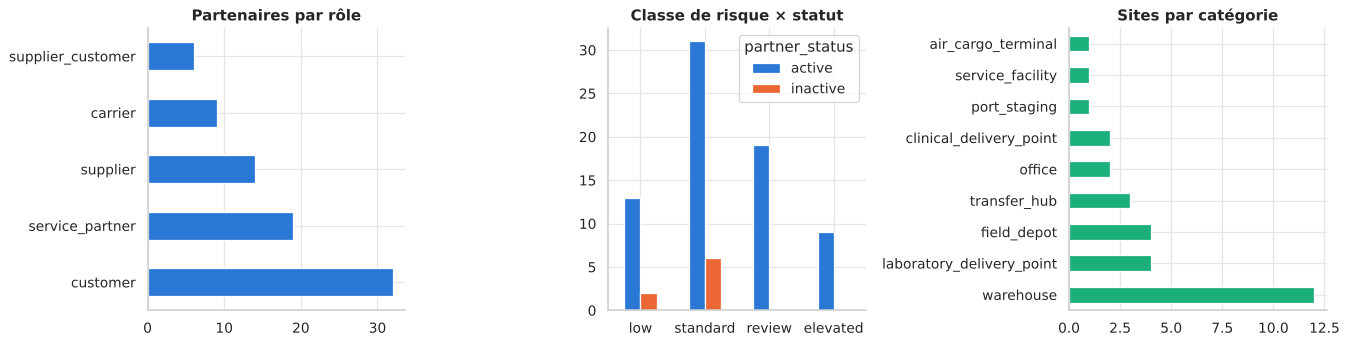

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
bpc = clean["erp_business_partners"]
bpc.partner_role.value_counts().plot.barh(ax=axes[0], color=PALETTE[0]); axes[0].set_title("Partenaires par rôle")
pd.crosstab(bpc.risk_class, bpc.partner_status).loc[["low", "standard", "review", "elevated"]].plot.bar(ax=axes[1], rot=0, color=PALETTE[:2])
axes[1].set_title("Classe de risque × statut")
clean["erp_facilities"].facility_category.value_counts().plot.barh(ax=axes[2], color=PALETTE[2]); axes[2].set_title("Sites par catégorie")
for a in axes: a.set_xlabel(""); a.set_ylabel("")
plt.tight_layout(); plt.show()

Surtout des clients (32) et des prestataires de services (19). 9 partenaires `elevated` et 19 `review`. Les 8 inactifs sont `standard` ou `low`. Côté sites, 12 entrepôts sur 30.

In [17]:
# partenaires les plus actifs
names = bpc.set_index("partner_code").partner_name
top = pd.DataFrame({
    "PO comme fournisseur": po.supplier_partner_code.value_counts(),
    "expéditions envoyées": sh.sender_partner_code.value_counts(),
    "expéditions reçues": sh.receiver_partner_code.value_counts(),
    "expéditions transportées": sh.carrier_partner_code.value_counts(),
}).fillna(0).astype(int)
top["total"] = top.sum(axis=1)
top.insert(0, "nom", names.reindex(top.index))
top.sort_values("total", ascending=False).head(8)

,nom,PO comme fournisseur,expéditions envoyées,expéditions reçues,expéditions transportées,total
BP-30078,Meridian BioLogistics,111,90,56,42,299
BP-30047,Northstar Cold Chain Services,7,3,5,85,100
BP-30056,Horizon Field Research Cooperative,27,35,20,0,82
BP-30021,Asterion Clinical Institute,11,4,58,0,73
BP-30042,Nivren Maritime Logistics,7,1,7,56,71
BP-30055,Silverline Courier Cooperative,7,6,4,52,69
BP-30015,Tembara Port Services,6,5,5,51,67
BP-30025,Amber Storage and Transit,7,4,0,50,61


Meridian BioLogistics (BP-30078) apparaît dans 299 flux, plus que les 4 suivants réunis. Il faudra tenir compte du volume quand on agrège par acteur (§12).

### 5.2 Commandes d'achat : montants, prix, délais

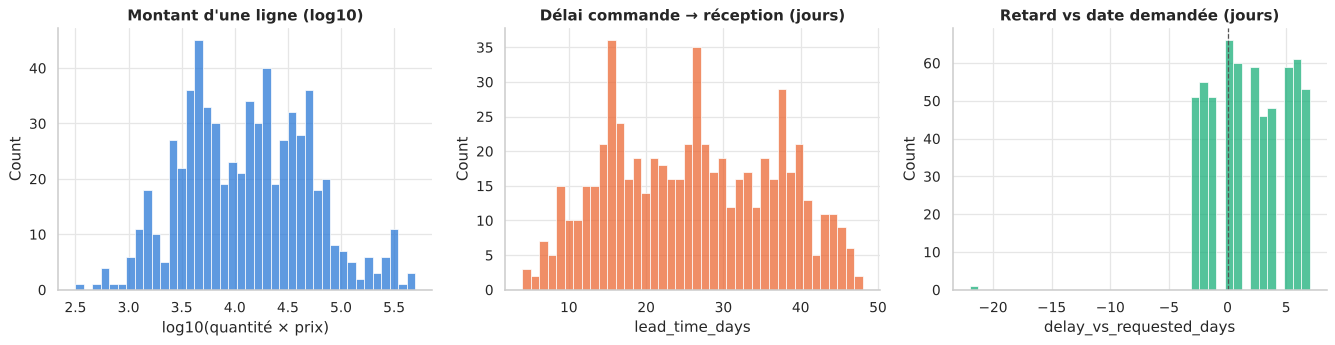

,ordered_quantity,unit_price,line_amount,lead_time_days,delay_vs_requested_days,qty_gap_pct
count,650.00,650.00,650.00,610.00,610.00,610.00
mean,20.96,3844.17,33904.22,25.95,1.97,-1.36
std,23.14,5701.54,62950.92,10.55,3.29,4.34
min,1.00,83.81,315.86,4.00,-22.00,-22.00
25%,1.00,560.44,4483.72,17.00,-1.00,0.00
50%,14.00,1600.67,13067.16,26.00,2.00,0.00
75%,30.00,4243.12,37007.30,35.00,5.00,0.00
max,90.00,28663.74,501871.96,48.00,7.00,0.00


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(np.log10(po_gr.line_amount), bins=40, ax=axes[0], color=PALETTE[0])
axes[0].set_title("Montant d'une ligne (log10)"); axes[0].set_xlabel("log10(quantité × prix)")
sns.histplot(po_gr.lead_time_days.dropna(), bins=40, ax=axes[1], color=PALETTE[1])
axes[1].set_title("Délai commande → réception (jours)")
sns.histplot(po_gr.delay_vs_requested_days.dropna(), bins=40, ax=axes[2], color=PALETTE[2])
axes[2].axvline(0, color="#555", ls="--", lw=1); axes[2].set_title("Retard vs date demandée (jours)")
plt.tight_layout(); plt.show()
po_gr[["ordered_quantity", "unit_price", "line_amount", "lead_time_days", "delay_vs_requested_days", "qty_gap_pct"]].describe().round(2)

- Montant très asymétrique (316 à 500 000, médiane 13 000) : on passe au log.
- Délai commande → réception : 4 à 48 jours, médiane 26.
- Retard par rapport à la date demandée : −22 à +7 jours, médiane +2.
- `qty_gap_pct` jamais positif : on ne reçoit jamais plus que commandé, parfois jusqu'à 22 % de moins.

In [19]:
# dispersion des prix par article
price_disp = (po_gr.groupby(["item_code", "item_description"]).unit_price
                .agg(n="size", median="median", min="min", max="max")
                .assign(ratio_max_median=lambda d: (d["max"] / d["median"]).round(1))
                .sort_values("ratio_max_median", ascending=False))
price_disp.head(10)

,,n,median,min,max,ratio_max_median
item_code,item_description,,,,,
ITM-AGR-001,Durian produce pallet,23,1824.430,1646.70,2118.23,1.2
ITM-CON-001,Operational consulting service,25,5375.580,4967.44,6409.83,1.2
ITM-CSE-001,Portable cold-storage module,27,12531.430,11398.01,14698.78,1.2
ITM-LAB-002,Sample preparation material pack,19,495.840,450.26,571.98,1.2
ITM-LAB-001,Laboratory assay material pack,25,725.960,654.05,842.95,1.2
ITM-AGR-002,Mixed orchard produce pallet,30,1351.485,1170.60,1525.44,1.1
ITM-AGE-001,Orchard maintenance equipment,23,5481.670,4797.82,6172.73,1.1
ITM-COM-001,Secure communication service,17,1554.150,1292.19,1673.00,1.1
ITM-BIO-003,Wildlife survey specimen lot,16,996.325,883.47,1116.46,1.1


Pour un même article, le prix max ne dépasse jamais 1,2 × la médiane. Pas de surfacturation visible.

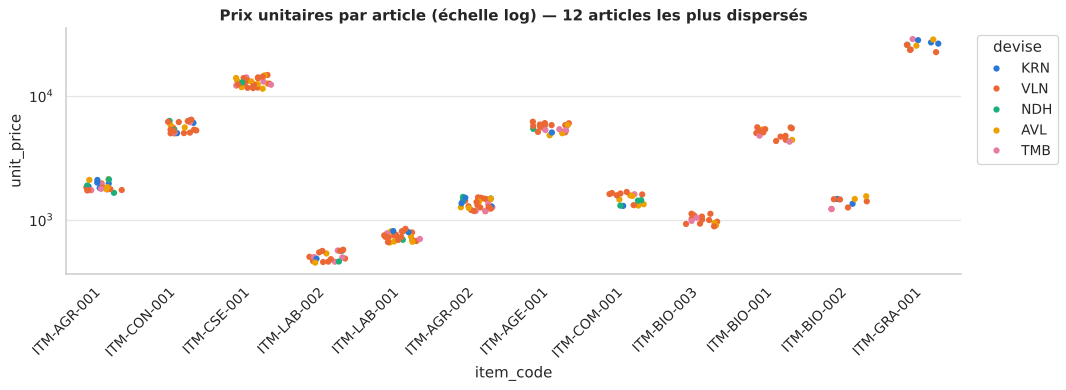

In [20]:
order = price_disp.index.get_level_values(0)[:12]
plt.figure(figsize=(12, 4.5))
sns.stripplot(data=po_gr[po_gr.item_code.isin(order)], x="item_code", y="unit_price", order=order,
              hue="currency", palette=PALETTE[:5], size=5, jitter=0.25)
plt.yscale("log"); plt.xticks(rotation=45, ha="right"); plt.title("Prix unitaires par article (échelle log) — 12 articles les plus dispersés")
plt.legend(title="devise", bbox_to_anchor=(1.01, 1), loc="upper left"); plt.tight_layout(); plt.show()

Pour chaque article les prix restent groupés, quelle que soit la devise.

Les prix sont en 5 devises sans taux de change. On vérifie si la devise explique une partie de la dispersion.

In [21]:
grp = po_gr.groupby(["item_code", "currency"]).unit_price
po_gr["price_ratio_item_cur"] = po_gr.unit_price / grp.transform("median")
po_gr["price_ratio_item"] = po_gr.unit_price / po_gr.groupby("item_code").unit_price.transform("median")
print("Écart-type de log(prix/médiane) — par article :", np.log(po_gr.price_ratio_item).std().round(3),
      "| par article×devise :", np.log(po_gr.price_ratio_item_cur).std().round(3))
print("Lignes dont le prix est > 3× la médiane (article, devise) :", (po_gr.price_ratio_item_cur > 3).sum())
print("Lignes dont le prix est < 1/3 de la médiane (article, devise) :", (po_gr.price_ratio_item_cur < 1/3).sum())

Écart-type de log(prix/médiane) — par article : 0.08 | par article×devise : 0.073
Lignes dont le prix est > 3× la médiane (article, devise) : 0
Lignes dont le prix est < 1/3 de la médiane (article, devise) : 0


L'écart-type baisse à peine (0,080 → 0,073) quand on contrôle la devise, et aucune ligne n'est à plus de 3× la médiane. La règle « prix anormal » du §6.2 ne se déclenchera donc pas.

### 5.3 Expéditions

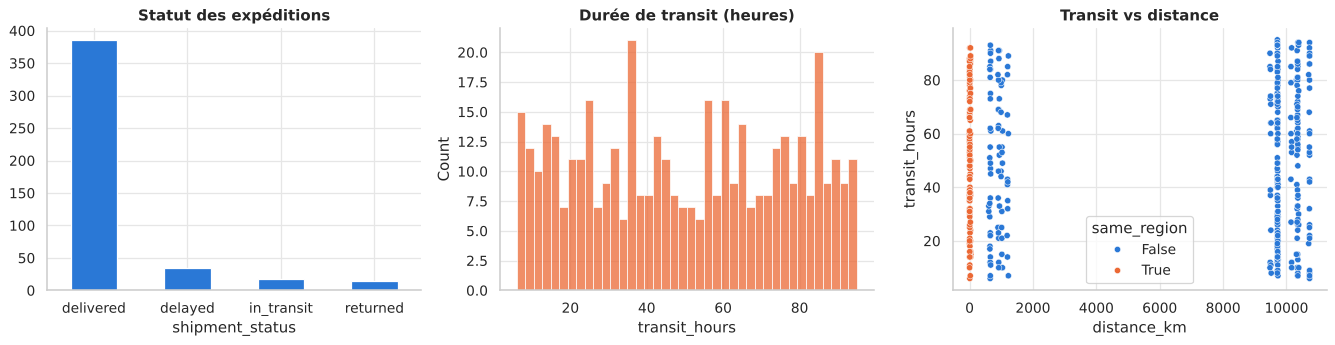

Corrélation de Spearman transit / distance : 0.014


latitude          longitude          
                                          min      max       min       max
region                                                                    
eastern avelora agricultural cluster   7.3451   7.5000  101.6200  101.9226
kintara karst cluster                  4.6435   4.7600  112.2424  112.3910
nordhaven maritime district           56.1606  56.5286    8.7405    9.0504
tembara coastal cluster                2.0992   2.5590  104.2706  104.5800
valenne central district              47.0273  47.2996    7.4900    7.8480

,declared_quantity,transit_hours,distance_km
count,450.0,433.0,450.0
mean,21.2,49.9,5792.2
std,23.5,26.3,4797.7
min,1.0,6.0,0.0
25%,2.0,26.0,607.7
50%,12.0,49.0,9711.3
75%,31.0,74.0,9732.5
max,90.0,95.0,10729.6


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sh.shipment_status.value_counts().plot.bar(ax=axes[0], rot=0, color=PALETTE[0]); axes[0].set_title("Statut des expéditions")
sns.histplot(sh.transit_hours.dropna(), bins=40, ax=axes[1], color=PALETTE[1]); axes[1].set_title("Durée de transit (heures)")
sns.scatterplot(data=sh, x="distance_km", y="transit_hours", hue="same_region", ax=axes[2], palette=PALETTE[:2], s=25)
axes[2].set_title("Transit vs distance")
plt.tight_layout(); plt.show()
print("Corrélation de Spearman transit / distance :", round(sh[["transit_hours", "distance_km"]].corr(method="spearman").iloc[0, 1], 3))
display(fac.groupby("region")[["latitude", "longitude"]].agg(["min", "max"]))
sh[["declared_quantity", "transit_hours", "distance_km"]].describe().round(1)

- 85 % livrées, ~11 % retardées ou retournées.
- Transit uniforme entre 6 et 95 h.
- Distances soit < 1 300 km soit ≈ 10 000 km, sans lien avec la durée de transit. Les sites de Valenne et Nordhaven sont placés en Europe alors que les autres sont en Asie du Sud-Est. Les coordonnées ne sont pas fiables, on n'utilise pas la distance dans les modèles.

In [23]:
# statut par catégorie (% en ligne)
ct = pd.crosstab(sh.item_category, sh.shipment_status, normalize="index").mul(100).round(1)
ct["n"] = sh.item_category.value_counts()
ct.sort_values("delivered")

shipment_status,delayed,delivered,in_transit,returned,n
item_category,,,,,
other,9.1,63.6,9.1,18.2,11
monitoring_equipment,21.4,73.8,2.4,2.4,42
communication_service,13.3,80.0,6.7,0.0,15
protective_equipment,8.0,80.0,12.0,0.0,25
legal_service,20.0,80.0,0.0,0.0,10
refrigeration_service,12.0,80.0,4.0,4.0,25
laboratory_material,12.9,80.6,6.5,0.0,31
office_supply,3.7,81.5,7.4,7.4,27
agricultural_product,11.4,81.8,0.0,6.8,44


`monitoring_equipment` est retardé dans 21 % des cas et `other` retourné dans 18 %. Les échantillons biologiques (98 %) et le matériel médical (100 %) sont presque toujours livrés. Petits effectifs (7 à 52 par catégorie), donc à prendre avec prudence.

### 5.4 Corrélations entre variables numériques

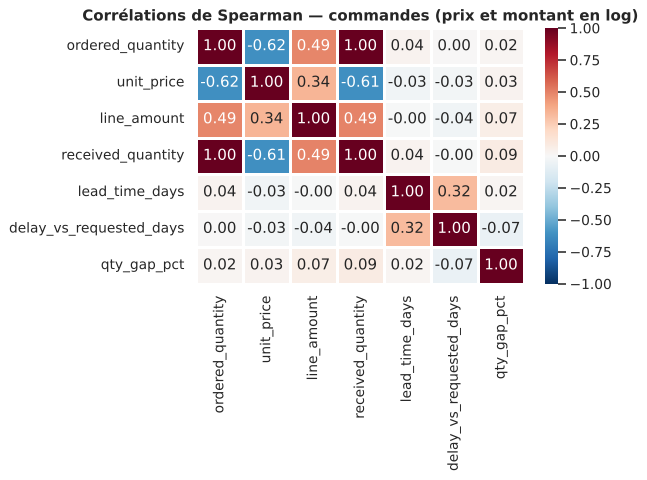

In [24]:
num = po_gr[["ordered_quantity", "unit_price", "line_amount", "received_quantity", "lead_time_days",
             "delay_vs_requested_days", "qty_gap_pct"]].copy()
num[["unit_price", "line_amount"]] = np.log10(num[["unit_price", "line_amount"]])
corr = num.corr(method="spearman")
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=1, linecolor="white")
plt.title("Corrélations de Spearman — commandes (prix et montant en log)"); plt.tight_layout(); plt.show()

Seulement des corrélations attendues : quantité commandée / reçue (1,00), quantité / prix (−0,62), délai / retard (0,32). L'écart de quantité n'est corrélé à rien.

## 6. Règles métier

Contrôles logiques : équilibre des stocks, chronologie, chaîne du froid, statut des partenaires. On s'en sert aussi pour comparer avec le §7.

### 6.1 Équilibre des stocks

`ouverture + reçu − sorti − usage interne − déchets = clôture`. Le résidu est l'écart entre clôture déclarée et clôture attendue. On vérifie aussi que la clôture d'un mois = l'ouverture du suivant.

In [25]:
inv = clean["inventory_month_end"].sort_values(["facility_code", "item_category", "reporting_month"]).copy()
inv["expected_closing"] = (inv.opening_stock + inv.received_quantity - inv.outgoing_quantity
                           - inv.documented_internal_use - inv.documented_waste)
inv["residual"] = (inv.closing_stock - inv.expected_closing).round(2)          # < 0 : stock disparu
inv["residual_pct_of_flow"] = 100 * inv.residual / (inv.opening_stock + inv.received_quantity).replace(0, np.nan)
inv["prev_closing"] = inv.groupby(["facility_code", "item_category"]).closing_stock.shift()
inv["continuity_gap"] = (inv.opening_stock - inv.prev_closing).round(2)
inv["negative_value"] = (inv[["opening_stock", "received_quantity", "outgoing_quantity", "documented_internal_use",
                              "documented_waste", "closing_stock"]] < 0).any(axis=1)

TOL = 0.05
print(f"Lignes de stock : {len(inv)}")
print(f"Résidu non nul (|écart| > {TOL}) : {(inv.residual.abs() > TOL).sum()} lignes")
print(f"Rupture de continuité ouverture ≠ clôture précédente : {(inv.continuity_gap.abs() > TOL).sum()}")
print(f"Valeurs négatives : {inv.negative_value.sum()}")
print("\nDistribution du résidu :"); print(inv.residual.describe().round(2).to_string())

Lignes de stock : 500
Résidu non nul (|écart| > 0.05) : 492 lignes
Rupture de continuité ouverture ≠ clôture précédente : 0
Valeurs négatives : 0

Distribution du résidu :
count    500.00
mean      -0.02
std        4.47
min      -21.80
25%       -1.21
50%        0.18
75%        1.66
max       44.37


492 lignes sur 500 ne s'équilibrent pas, mais la continuité entre mois est parfaite et il n'y a pas de valeur négative. Le résidu est centré sur 0 (écart-type 4,5, min −21,8, max +44,4) : beaucoup de petit bruit et quelques gros écarts.

Pour séparer le bruit des vrais écarts on utilise un z-score robuste (médiane et MAD) avec |z| > 3. Résidu négatif = stock disparu.

In [26]:
med = inv.residual.median(); mad = 1.4826 * (inv.residual - med).abs().median()
inv["residual_z"] = (inv.residual - med) / mad
inv["shortfall"] = inv.residual_z < -3          # disparition significative
inv["surplus"] = inv.residual_z > 3             # apparition significative
print(f"MAD robuste = {mad:.2f} unités → seuil |z|>3 ≈ {3*mad:.1f} unités")
print(f"Disparitions significatives : {inv.shortfall.sum()} | apparitions significatives : {inv.surplus.sum()}")
tab = inv.groupby(["facility_code", "item_category"]).agg(n_disparitions=("shortfall", "sum"), n_apparitions=("surplus", "sum"),
                                                         residu_total=("residual", "sum")).round(1)
tab.sort_values("n_disparitions", ascending=False).head(10)

MAD robuste = 2.16 unités → seuil |z|>3 ≈ 6.5 unités
Disparitions significatives : 25 | apparitions significatives : 13


n_disparitions  n_apparitions  residu_total
facility_code item_category                                                    
FCL-1010      medical_consumables                5              0         -82.2
FCL-1027      biological_sample                  5              1         -25.2
FCL-1020      biological_sample                  4              0         -38.7
FCL-1019      biological_sample                  3              0         -42.6
FCL-1024      biological_sample                  2              2           2.7
FCL-1020      monitoring_equipment               2              0          -8.7
FCL-1019      monitoring_equipment               1              1          -3.6
FCL-1027      monitoring_equipment               1              0         -22.1
              agricultural_product               1              0           3.0
FCL-1019      protective_equipment               1              0          -5.5

Seuil ≈ 6,5 unités : 25 disparitions et 13 surplus. Les disparitions sont concentrées :
- échantillons biologiques dans les hubs Meridian (FCL-1019, 1020, 1027, 1024) : 14 sur 25, résidu cumulé −42,6 (FCL-1019) et −38,7 (FCL-1020) ;
- consommables médicaux à FCL-1010 : 5 disparitions, −82 au total.

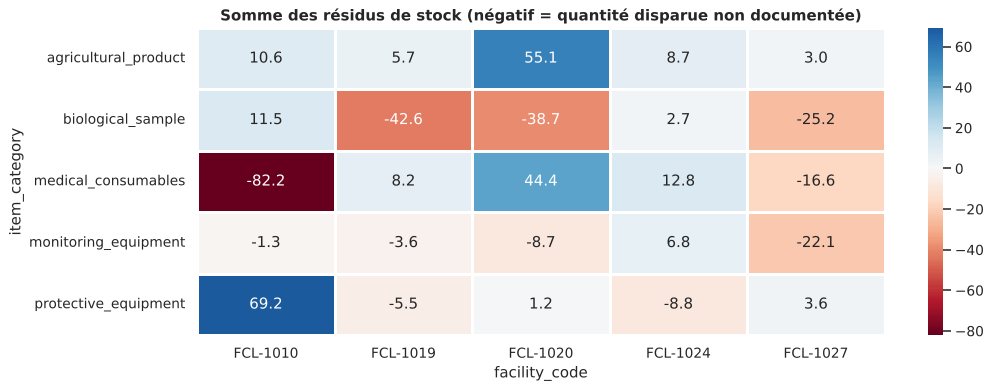

In [27]:
fig, ax = plt.subplots(figsize=(12, 4.5))
pv = inv.pivot_table(index="item_category", columns="facility_code", values="residual", aggfunc="sum")
sns.heatmap(pv, annot=True, fmt=".1f", cmap="RdBu", center=0, linewidths=1, linecolor="white", ax=ax)
ax.set_title("Somme des résidus de stock (négatif = quantité disparue non documentée)"); plt.tight_layout(); plt.show()

En négatif : `biological_sample` à FCL-1019/1020/1027 et `medical_consumables` à FCL-1010. En positif : FCL-1010 `protective_equipment` (+69) et FCL-1020 `agricultural_product` (+55). FCL-1010 perd des consommables et gagne du matériel de protection, peut-être un reclassement entre catégories.

In [28]:
inv[inv.shortfall].sort_values("residual")[
    ["facility_code", "reporting_month", "item_category", "opening_stock", "received_quantity", "outgoing_quantity",
     "documented_internal_use", "documented_waste", "closing_stock", "expected_closing", "residual", "inventory_status"]].head(15)

,facility_code,reporting_month,item_category,opening_stock,received_quantity,outgoing_quantity,documented_internal_use,documented_waste,closing_stock,expected_closing,residual,inventory_status
106,FCL-1019,2019-11-01,biological_sample,28.43,7.00,7.00,2.77,0.48,3.38,25.18,-21.80,closed
1,FCL-1024,2018-03-01,biological_sample,16.24,5.00,0.00,1.94,0.65,0.55,18.65,-18.10,closed
334,FCL-1010,2023-11-01,medical_consumables,258.70,81.00,0.70,39.01,11.61,270.62,288.38,-17.76,revised
102,FCL-1019,2018-05-01,biological_sample,57.30,3.00,3.00,9.21,0.14,30.32,47.95,-17.63,closed
450,FCL-1027,2021-05-01,monitoring_equipment,24.51,11.49,0.19,1.95,0.21,16.42,33.65,-17.23,revised
156,FCL-1019,2024-05-01,monitoring_equipment,99.39,9.25,0.00,13.23,4.88,73.84,90.53,-16.69,revised
338,FCL-1010,2025-04-01,medical_consumables,185.89,0.00,3.15,15.33,8.48,145.00,158.93,-13.93,revised
337,FCL-1010,2024-08-01,medical_consumables,237.31,7.53,1.56,41.59,2.16,185.89,199.53,-13.64,closed
217,FCL-1020,2024-08-01,biological_sample,13.54,3.00,3.00,0.76,0.42,0.00,12.36,-12.36,closed
324,FCL-1010,2019-08-01,medical_consumables,70.38,0.00,0.86,8.08,1.08,48.04,60.36,-12.32,closed


Exemple : en novembre 2019 à FCL-1019, on attendait 25,2 lots d'échantillons biologiques et la clôture est de 3,4, soit 21,8 lots manquants. Environ la moitié de ces lignes ont le statut `revised`.

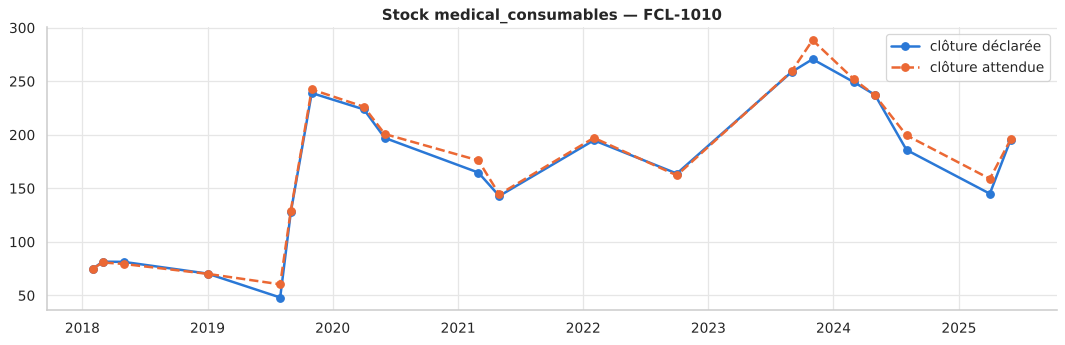

In [29]:
# site x catégorie avec le plus de disparitions
worst = inv.groupby(["facility_code", "item_category"]).shortfall.sum().idxmax()
w = inv[(inv.facility_code == worst[0]) & (inv.item_category == worst[1])]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(w.reporting_month, w.closing_stock, marker="o", label="clôture déclarée", color=PALETTE[0])
ax.plot(w.reporting_month, w.expected_closing, marker="o", ls="--", label="clôture attendue", color=PALETTE[1])
ax.set_title(f"Stock {worst[1]} — {worst[0]}"); ax.legend(); plt.tight_layout(); plt.show()

Pour les consommables médicaux à FCL-1010, quand il y a un écart la clôture déclarée est toujours en dessous de l'attendu, jamais au-dessus. Perte répétée sur plusieurs années, plus marquée depuis fin 2023.

### 6.2 Règles sur commandes, réceptions et expéditions

In [30]:
bpi = clean["erp_business_partners"].set_index("partner_code")
rules_po = pd.DataFrame(index=po_gr.index)
rules_po["réception avant commande"] = po_gr.lead_time_days < 0
rules_po["quantité reçue ≠ commandée (>5%)"] = po_gr.qty_gap_pct.abs() > 5
rules_po["unité reçue ≠ unité commandée"] = po_gr.unit_mismatch
rules_po["fournisseur réception ≠ commande"] = po_gr.supplier_mismatch
rules_po["site réception ≠ site commande"] = po_gr.facility_mismatch
rules_po["prix > 3× médiane article/devise"] = po_gr.price_ratio_item_cur > 3
rules_po["fournisseur inactif"] = po_gr.supplier_partner_code_po.map(bpi.partner_status).eq("inactive")
rules_po["commande avant référencement fournisseur"] = po_gr.order_date < po_gr.supplier_partner_code_po.map(bpi.onboarding_date)
rules_po["réception en quarantaine / retenue"] = po_gr.inspection_status.isin(["held"]) | po_gr.receipt_status.eq("quality_hold")
rules_po["centre de coût manquant"] = po_gr.declared_cost_center.isna()
po_gr["n_rule_flags"] = rules_po.sum(axis=1)
print("Commandes à des fournisseurs aujourd'hui inactifs, par année :", po_gr[rules_po["fournisseur inactif"]].year.value_counts().sort_index().to_dict())
display(po_gr[rules_po["commande avant référencement fournisseur"]][["purchase_order_number", "order_date", "supplier_partner_code_po", "item_description"]]
        .assign(onboarding=lambda d: d.supplier_partner_code_po.map(bpi.onboarding_date), risk=lambda d: d.supplier_partner_code_po.map(bpi.risk_class)))
rules_po.sum().sort_values(ascending=False).to_frame("nb commandes")

Commandes à des fournisseurs aujourd'hui inactifs, par année : {2015: 1, 2016: 1, 2017: 3, 2018: 8, 2019: 3, 2020: 11, 2021: 10, 2022: 9, 2023: 9, 2024: 6, 2025: 8}


,purchase_order_number,order_date,supplier_partner_code_po,item_description,onboarding,risk
8,PO-2015-00008,2015-05-01,BP-30028,Field camera and sensor kit,2019-05-01,elevated
11,PO-2015-00011,2015-06-24,BP-30009,Applied research contract,2016-10-01,low
19,PO-2015-00019,2015-10-31,BP-30009,Durian produce pallet,2016-10-01,low
36,PO-2016-00010,2016-03-26,BP-30054,Office supply case,2016-07-01,review
37,PO-2016-00011,2016-04-19,BP-30028,Programme grant transfer,2019-05-01,elevated
49,PO-2016-00023,2016-11-14,BP-30048,Environmental reference sample lot,2018-01-01,standard
56,PO-2017-00002,2017-01-17,BP-30008,General facility material,2019-09-01,low
91,PO-2018-00011,2018-04-03,BP-30028,Regulatory legal service,2019-05-01,elevated
127,PO-2018-00047,2018-07-26,BP-30008,Diagnostic equipment unit,2019-09-01,low
128,PO-2018-00048,2018-09-03,BP-30008,General facility material,2019-09-01,low


,nb commandes
fournisseur inactif,69
quantité reçue ≠ commandée (>5%),62
réception en quarantaine / retenue,34
commande avant référencement fournisseur,10
centre de coût manquant,3
réception avant commande,0
prix > 3× médiane article/devise,0
site réception ≠ site commande,0
fournisseur réception ≠ commande,0
unité reçue ≠ unité commandée,0


- 69 commandes à des fournisseurs aujourd'hui inactifs, jusqu'en 2025. On n'a pas l'historique des statuts, mais c'est suspect.
- 10 commandes passées avant le référencement du fournisseur, jusqu'à 4 ans avant pour BP-30028 (classé `elevated`).
- 62 sous-livraisons > 5 %, la plupart acceptées à l'inspection.
- Aucune incohérence fournisseur / site / unité / date entre commande et réception.

In [31]:
def caps_ok(temp, caps):
    if temp == "2-8C": return "2-8C" in caps
    if temp == "frozen": return "frozen" in caps
    return True
rules_sh = pd.DataFrame(index=sh.index)
rules_sh["arrivée avant départ"] = sh.transit_hours < 0
rules_sh["livré sans date d'arrivée"] = sh.arrival_time.isna() & sh.shipment_status.eq("delivered")
rules_sh["destination sans capacité de température"] = [not caps_ok(t, c) for t, c in zip(sh.temperature_control_class, sh.destination_caps)]
rules_sh["origine sans capacité de température"] = [not caps_ok(t, c) for t, c in zip(sh.temperature_control_class, sh.origin_caps)]
rules_sh["échantillon biologique hors froid"] = sh.item_category.eq("biological_sample") & sh.temperature_control_class.eq("ambient")
rules_sh["transporteur sans rôle 'carrier'"] = ~sh.carrier_partner_code.map(bpi.partner_role).eq("carrier")
rules_sh["partenaire inactif"] = (sh.sender_partner_code.map(bpi.partner_status).eq("inactive") |
                                  sh.receiver_partner_code.map(bpi.partner_status).eq("inactive"))
rules_sh["site d'origine pas encore ouvert"] = sh.dispatch_time < sh.origin_facility_code.map(fac.opening_date)
rules_sh["partenaire à risque élevé"] = (sh.sender_partner_code.map(bpi.risk_class).eq("elevated") |
                                        sh.receiver_partner_code.map(bpi.risk_class).eq("elevated"))
rules_sh["expédition vers soi-même"] = sh.origin_facility_code.eq(sh.destination_facility_code)
sh["n_rule_flags"] = rules_sh.drop(columns=["partenaire à risque élevé"]).sum(axis=1)
rules_sh.sum().sort_values(ascending=False).to_frame("nb expéditions")

,nb expéditions
partenaire à risque élevé,80
origine sans capacité de température,71
destination sans capacité de température,29
expédition vers soi-même,22
livré sans date d'arrivée,0
arrivée avant départ,0
transporteur sans rôle 'carrier',0
échantillon biologique hors froid,0
site d'origine pas encore ouvert,0
partenaire inactif,0


- 71 expéditions sous température dirigée partent d'un site sans cette capacité, 29 arrivent dans un site qui ne l'a pas.
- 22 expéditions ont la même origine et destination.
- Aucune violation pour les autres contrôles. Les 17 expéditions sans date d'arrivée sont bien `in_transit`.
- 80 expéditions impliquent un partenaire `elevated` (utilisé seulement dans le score final).

In [32]:
# origine des envois froids sans froid + envois vers soi-même
o = sh[rules_sh["origine sans capacité de température"]]
display(o.groupby(["origin_facility_code"]).agg(site=("origin_facility_code", lambda s: fac.facility_name[s.iloc[0]]),
        capacites=("origin_caps", "first"), n=("shipment_number", "size")).sort_values("n", ascending=False).head(5))
sh[rules_sh["expédition vers soi-même"]].groupby(["origin_facility_code", "item_category", "declared_purpose"]).size().sort_values(ascending=False).head(8).to_frame("n")

,site,capacites,n
origin_facility_code,,,
FCL-1011,Meridian Valenne Headquarters,ambient,43
FCL-1030,Kintara Cave Authority Field Depot,ambient,14
FCL-1002,Lumen Safety Equipment Store,ambient;secure_cage,3
FCL-1029,Vale Strategy Valenne Office,,2
FCL-1013,Nordhaven Refrigeration Workshop,ambient,2


n
origin_facility_code item_category          declared_purpose                                 
FCL-1019             biological_sample      environmental and wildlife reference materials  7
FCL-1020             biological_sample      environmental and wildlife reference materials  4
FCL-1010             research_contract      customer distribution                           1
                     refrigeration_service  field programme support                         1
                     protective_equipment   agricultural distribution                       1
FCL-1011             medical_consumables    scheduled stock transfer                        1
                     agricultural_product   customer distribution                           1
FCL-1015             cold_storage_equipment laboratory delivery                             1

- 43 de ces envois froids partent du siège Meridian (FCL-1011, un bureau `ambient`). Probablement un mauvais site rattaché dans l'ERP.
- Les envois vers soi-même sont surtout des échantillons biologiques (« environmental and wildlife reference materials ») à FCL-1019 et FCL-1020 (11 cas). Ce sont les mêmes sites que les disparitions de stock du §6.1.

In [33]:
# détail chaîne du froid
cols = ["shipment_number", "dispatch_time", "item_category", "temperature_control_class", "origin_facility_code",
        "destination_facility_code", "destination_category", "destination_caps", "declared_purpose", "authorization_class", "shipment_status"]
sh.loc[rules_sh["destination sans capacité de température"] | rules_sh["échantillon biologique hors froid"]
       | rules_sh["arrivée avant départ"], cols].sort_values("dispatch_time")

,shipment_number,dispatch_time,item_category,temperature_control_class,origin_facility_code,destination_facility_code,destination_category,destination_caps,declared_purpose,authorization_class,shipment_status
1,SHP-2015-00001,2015-01-10 11:00:00,medical_consumables,2-8C,FCL-1009,FCL-1013,service_facility,ambient,scheduled stock transfer,ordinary,returned
3,SHP-2015-00003,2015-02-17 15:00:00,biological_sample,2-8C,FCL-1019,FCL-1011,office,ambient,laboratory delivery,restricted,delivered
17,SHP-2015-00017,2015-12-26 07:00:00,medical_consumables,2-8C,FCL-1013,FCL-1029,office,,agricultural distribution,ordinary,delivered
27,SHP-2016-00010,2016-09-12 17:00:00,medical_consumables,2-8C,FCL-1011,FCL-1011,office,ambient,scheduled stock transfer,restricted,returned
35,SHP-2017-00001,2017-01-18 07:00:00,medical_consumables,2-8C,FCL-1006,FCL-1030,field_depot,ambient,scheduled stock transfer,ordinary,delivered
46,SHP-2017-00012,2017-08-17 06:00:00,medical_consumables,2-8C,FCL-1007,FCL-1011,office,ambient,agricultural distribution,ordinary,delivered
100,SHP-2018-00047,2018-12-29 11:00:00,agricultural_product,frozen,FCL-1011,FCL-1011,office,ambient,customer distribution,expedited,delivered
113,SHP-2019-00013,2019-09-02 08:00:00,medical_consumables,2-8C,FCL-1003,FCL-1030,field_depot,ambient,facility replenishment,ordinary,delivered
116,SHP-2019-00016,2019-09-02 14:00:00,agricultural_product,frozen,FCL-1011,FCL-1007,clinical_delivery_point,2-8C;controlled_access,facility replenishment,ordinary,returned
127,SHP-2019-00027,2019-09-13 11:00:00,medical_consumables,2-8C,FCL-1011,FCL-1002,warehouse,ambient;secure_cage,scheduled stock transfer,ordinary,returned


Exemples d'échantillons 2-8 °C envoyés vers des bureaux (FCL-1011) ou des dépôts sans froid (FCL-1021, 1005, 1030), parfois avec un motif qui ne colle pas. FCL-1029 a des capacités vides (valeur manquante du §2.1).

### 6.3 Ajustements de stock

Signe, motif, approbateur et pièce justificative de chaque ajustement.

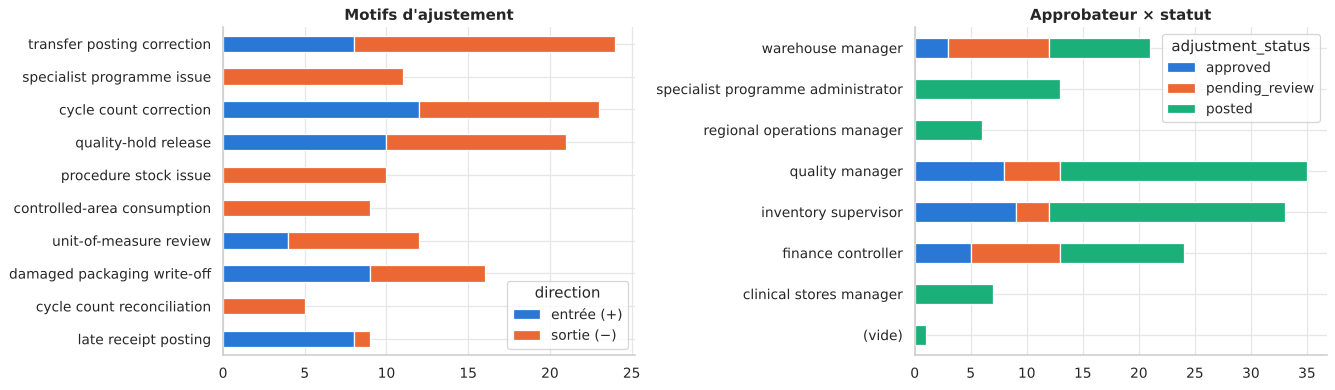

Ajustements sans pièce justificative : 85 / 140


count    sum
facility_code item_category                     
FCL-1010      medical_consumables      16 -33.55
FCL-1007      medical_consumables      14 -29.35
FCL-1024      biological_sample         8 -18.44
FCL-1019      biological_sample         8 -16.80
FCL-1005      biological_sample         2 -12.72
FCL-1020      biological_sample         5 -12.46
FCL-1023      medical_consumables       2 -10.20
              agricultural_product      2  -9.99

In [34]:
adj = clean["inventory_adjustments"].copy()
adj["direction"] = np.where(adj.adjustment_quantity < 0, "sortie (−)", "entrée (+)")
adj["justified"] = adj.related_receipt_number.notna() | adj.related_shipment_number.notna()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
pd.crosstab(adj.adjustment_reason, adj.direction).sort_values("sortie (−)").plot.barh(stacked=True, ax=axes[0], color=PALETTE[:2])
axes[0].set_title("Motifs d'ajustement"); axes[0].set_ylabel("")
pd.crosstab(adj.approved_by_role.fillna("(vide)"), adj.adjustment_status).plot.barh(stacked=True, ax=axes[1], color=PALETTE[:3])
axes[1].set_title("Approbateur × statut"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()
print("Ajustements sans pièce justificative :", (~adj.justified).sum(), "/", len(adj))
adj.groupby(["facility_code", "item_category"]).adjustment_quantity.agg(["count", "sum"]).round(2).sort_values("sum").head(8)

89 ajustements sur 140 sont des sorties (−284 contre +201). 85 (61 %) n'ont aucune pièce justificative. Les plus grosses sorties sont à FCL-1010 et FCL-1007 (consommables médicaux) et dans les hubs Meridian (échantillons biologiques). 25 sont encore `pending_review`.

In [35]:
# motif x approbateur
pd.crosstab(adj.adjustment_reason, adj.approved_by_role.fillna("(vide)"))

approved_by_role,(vide),clinical stores manager,finance controller,inventory supervisor,quality manager,regional operations manager,specialist programme administrator,warehouse manager
adjustment_reason,,,,,,,,
controlled-area consumption,0,3,0,0,3,0,3,0
cycle count correction,1,0,5,5,6,0,0,6
cycle count reconciliation,0,0,0,1,1,3,0,0
damaged packaging write-off,0,0,3,4,5,0,0,4
late receipt posting,0,0,3,3,1,0,0,2
procedure stock issue,0,1,0,0,4,0,5,0
quality-hold release,0,0,6,8,4,0,0,3
specialist programme issue,0,3,0,0,3,0,5,0
transfer posting correction,0,0,5,6,7,3,0,3


Les approbateurs sont globalement cohérents avec les motifs. Mais `specialist programme issue` et `controlled-area consumption` sont approuvés par l'administrateur du programme lui-même (pas de séparation des tâches), et un ajustement n'a pas d'approbateur.

On vérifie que la pièce citée concerne le même site et qu'elle est antérieure à l'ajustement.

In [36]:
gr_ref = gr.set_index("receipt_number")[["receipt_date", "receiving_facility_code"]]
sh_ref = sh.set_index("shipment_number")[["dispatch_time", "origin_facility_code", "destination_facility_code"]]
a_r = adj.dropna(subset=["related_receipt_number"]).join(gr_ref, on="related_receipt_number")
a_s = adj.dropna(subset=["related_shipment_number"]).join(sh_ref, on="related_shipment_number")
a_r["autre_site"] = a_r.facility_code != a_r.receiving_facility_code
a_r["avant_la_piece"] = a_r.adjustment_date < a_r.receipt_date
a_s["autre_site"] = (a_s.facility_code != a_s.origin_facility_code) & (a_s.facility_code != a_s.destination_facility_code)
a_s["avant_la_piece"] = a_s.adjustment_date < a_s.dispatch_time
linked = pd.DataFrame({
    "ajustements liés": [len(a_r), len(a_s)],
    "pièce d'un autre site": [a_r.autre_site.sum(), a_s.autre_site.sum()],
    "ajustement antérieur à la pièce": [a_r.avant_la_piece.sum(), a_s.avant_la_piece.sum()],
}, index=["→ réception", "→ expédition"])
adj["pièce_incohérente"] = adj.index.isin(a_r[a_r.autre_site | a_r.avant_la_piece].index) | adj.index.isin(a_s[a_s.autre_site | a_s.avant_la_piece].index)
linked

,ajustements liés,pièce d'un autre site,ajustement antérieur à la pièce
→ réception,23,21,11
→ expédition,37,18,14


Réceptions : 21 ajustements sur 23 citent une réception d'un autre site, 11 sont antérieurs à la réception. Expéditions : 18 sur 37 citent une expédition qui ne passe pas par le site, 14 sont antérieurs. Le champ « pièce liée » n'est pas fiable.

In [37]:
# disparitions du §6.1 avec un ajustement le même mois ?
adj["month"] = adj.adjustment_date.dt.to_period("M").dt.to_timestamp()
adj_m = adj.groupby(["facility_code", "item_category", "month"]).adjustment_quantity.sum().rename("adj_qty")
inv = inv.merge(adj_m, left_on=["facility_code", "item_category", "reporting_month"], right_index=True, how="left")
gap = inv[inv.shortfall]
print(f"Mois avec disparition significative : {len(gap)} | dont couverts par un ajustement le même mois : {gap.adj_qty.notna().sum()}")

Mois avec disparition significative : 25 | dont couverts par un ajustement le même mois : 8


8 disparitions sur 25 ont un ajustement le même mois. Les 17 autres ne sont expliquées par rien.

## 7. Détection d'anomalies non supervisée

Deux méthodes : Isolation Forest (anomalies globales) et LOF (anomalies par rapport aux voisins). Variables asymétriques passées au log, tout est standardisé.

### 7.1 Expéditions

In [38]:
num_sh = ["log_qty", "transit_hours_f", "hour", "weekday"]   # distance exclue : coordonnées non fiables (§5.3)
cat_sh = ["item_category", "temperature_control_class", "authorization_class", "declared_purpose",
          "origin_category", "destination_category", "declared_unit"]
X_sh = sh.copy()
X_sh["log_qty"] = np.log1p(X_sh.declared_quantity)
X_sh["transit_hours_f"] = X_sh.transit_hours.fillna(X_sh.transit_hours.median())
X_sh["hour"] = X_sh.dispatch_time.dt.hour
X_sh["weekday"] = X_sh.dispatch_time.dt.weekday
X_sh["year"] = X_sh.dispatch_time.dt.year
X_sh[cat_sh] = X_sh[cat_sh].astype(object).fillna("missing")
print("Valeurs manquantes restantes :", X_sh[num_sh].isna().sum().to_dict())
pre_sh = ColumnTransformer([("num", StandardScaler(), num_sh),
                            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_sh)])
Z_sh = pre_sh.fit_transform(X_sh[num_sh + cat_sh])

CONTAM = 0.05
iso = IsolationForest(n_estimators=500, contamination=CONTAM, random_state=RANDOM_STATE).fit(Z_sh)
sh["iso_score"] = -iso.score_samples(Z_sh)                    # plus grand = plus anormal
sh["iso_flag"] = iso.predict(Z_sh) == -1
lof = LocalOutlierFactor(n_neighbors=20, contamination=CONTAM)
sh["lof_flag"] = lof.fit_predict(Z_sh) == -1
sh["lof_score"] = -lof.negative_outlier_factor_
print("Isolation Forest :", sh.iso_flag.sum(), "| LOF :", sh.lof_flag.sum(), "| les deux :", (sh.iso_flag & sh.lof_flag).sum())

Valeurs manquantes restantes : {'log_qty': 0, 'transit_hours_f': 0, 'hour': 0, 'weekday': 0}
Isolation Forest : 23 | LOF : 23 | les deux : 7


Contamination 5 % : 23 expéditions pour chaque méthode, ~7 en commun. Les deux méthodes ne cherchent pas la même chose.

In [39]:
# anomalies IF vs règles métier
sh["any_rule"] = sh.n_rule_flags > 0
pd.crosstab(sh.iso_flag, sh.any_rule, margins=True, normalize=False).rename_axis(index="IsolationForest", columns="≥1 règle violée")

≥1 règle violée,False,True,All
IsolationForest,,,
False,330,97,427
True,15,8,23
All,345,105,450


Environ un tiers des anomalies IF violent une règle, contre ~23 % pour les autres. Peu de recouvrement : règles et modèle trouvent des choses différentes.

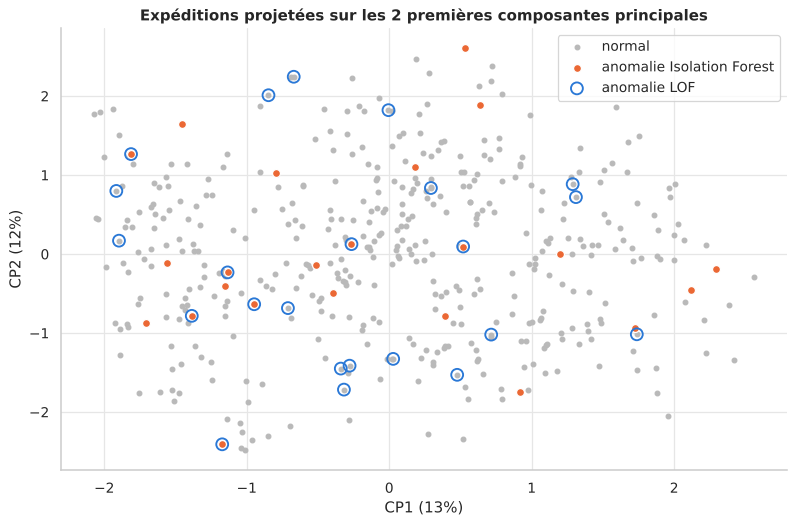

In [40]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(Z_sh)
P2 = pca.transform(Z_sh)
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(P2[~sh.iso_flag, 0], P2[~sh.iso_flag, 1], s=14, c="#b9b9b9", label="normal")
ax.scatter(P2[sh.iso_flag, 0], P2[sh.iso_flag, 1], s=40, c=PALETTE[1], edgecolor="white", label="anomalie Isolation Forest")
ax.scatter(P2[sh.lof_flag, 0], P2[sh.lof_flag, 1], s=90, facecolors="none", edgecolor=PALETTE[0], lw=1.5, label="anomalie LOF")
ax.set_xlabel(f"CP1 ({pca.explained_variance_ratio_[0]:.0%})"); ax.set_ylabel(f"CP2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("Expéditions projetées sur les 2 premières composantes principales"); ax.legend(); plt.tight_layout(); plt.show()

Les 2 premières composantes n'expliquent que ~25 % de la variance, les anomalies ne ressortent pas bien en 2D.

In [41]:
sh.sort_values("iso_score", ascending=False)[["shipment_number", "dispatch_time", "item_category", "declared_quantity",
    "declared_unit", "temperature_control_class", "authorization_class", "declared_purpose", "origin_category",
    "destination_category", "transit_hours", "shipment_status", "n_rule_flags", "iso_score", "lof_flag"]].head(12)

,shipment_number,dispatch_time,item_category,declared_quantity,declared_unit,temperature_control_class,authorization_class,declared_purpose,origin_category,destination_category,transit_hours,shipment_status,n_rule_flags,iso_score,lof_flag
303,SHP-2023-00008,2023-04-03 18:00:00,biological_sample,13.0,sealed_lot,2-8C,emergency,customer distribution,office,transfer_hub,9.0,delivered,1,0.477993,True
34,SHP-2016-00017,2016-12-20 08:00:00,biological_sample,17.0,sealed_lot,2-8C,emergency,facility replenishment,warehouse,clinical_delivery_point,14.0,delivered,1,0.470459,True
181,SHP-2020-00036,2020-05-28 08:00:00,medical_consumables,69.0,case,2-8C,expedited,field programme support,clinical_delivery_point,service_facility,71.0,delivered,1,0.470374,False
356,SHP-2023-00061,2023-09-15 11:00:00,agricultural_product,47.0,pallet,frozen,ordinary,agricultural distribution,port_staging,office,70.0,delivered,2,0.470187,False
65,SHP-2018-00012,2018-04-07 07:00:00,transport_service,1.0,service,ambient,emergency,agricultural distribution,air_cargo_terminal,transfer_hub,75.0,delivered,0,0.468612,False
410,SHP-2024-00042,2024-07-07 15:00:00,laboratory_material,60.0,pack,ambient,restricted,laboratory delivery,field_depot,clinical_delivery_point,7.0,delivered,0,0.468497,False
228,SHP-2021-00037,2021-07-09 11:00:00,agricultural_product,4.0,pallet,ambient,restricted,customer distribution,clinical_delivery_point,service_facility,74.0,returned,0,0.467628,False
100,SHP-2018-00047,2018-12-29 11:00:00,agricultural_product,13.0,pallet,frozen,expedited,customer distribution,office,office,32.0,delivered,3,0.466138,False
331,SHP-2023-00036,2023-06-24 17:00:00,research_contract,1.0,contract,ambient,emergency,agricultural distribution,office,transfer_hub,23.0,delayed,0,0.465539,True
3,SHP-2015-00003,2015-02-17 15:00:00,biological_sample,2.0,sealed_lot,2-8C,restricted,laboratory delivery,transfer_hub,office,41.0,delivered,1,0.465482,True


Les plus atypiques : échantillons biologiques en `emergency` depuis un bureau ou un entrepôt sans froid, surgelés vers un bureau, contrats de recherche avec le motif « agricultural distribution ». On retrouve FCL-1011 et FCL-1019.

### 7.2 Commandes d'achat

In [42]:
# seulement les commandes réceptionnées (sinon les délais manquants dominent)
X_po = po_gr[po_gr.receipt_number.notna()].copy()
X_po["log_price_ratio"] = np.log(X_po.price_ratio_item_cur)
X_po["log_amount"] = np.log10(X_po.line_amount)
X_po["log_qty"] = np.log1p(X_po.ordered_quantity)
for c in ["lead_time_days", "delay_vs_requested_days", "qty_gap_pct"]:
    X_po[c + "_f"] = X_po[c].fillna(X_po[c].median())
num_po = ["log_price_ratio", "log_amount", "log_qty", "lead_time_days_f", "delay_vs_requested_days_f", "qty_gap_pct_f"]
cat_po = ["item_category", "authorization_class", "declared_cost_center", "inspection_status"]
X_po[cat_po] = X_po[cat_po].astype(object).fillna("missing")
pre_po = ColumnTransformer([("num", StandardScaler(), num_po),
                            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_po)])
Z_po = pre_po.fit_transform(X_po[num_po + cat_po])
iso_po = IsolationForest(n_estimators=500, contamination=CONTAM, random_state=RANDOM_STATE).fit(Z_po)
po_gr["iso_score"] = pd.Series(-iso_po.score_samples(Z_po), index=X_po.index)
po_gr["iso_flag"] = pd.Series(iso_po.predict(Z_po) == -1, index=X_po.index).reindex(po_gr.index, fill_value=False)
print("Commandes anormales (Isolation Forest) :", po_gr.iso_flag.sum())
print("Taux de règle violée — anormales :", (po_gr[po_gr.iso_flag].n_rule_flags > 0).mean().round(2),
      "| normales :", (po_gr[~po_gr.iso_flag].n_rule_flags > 0).mean().round(2))
po_gr.sort_values("iso_score", ascending=False)[["purchase_order_number", "order_date", "item_description", "ordered_quantity",
    "unit_price", "currency", "price_ratio_item_cur", "qty_gap_pct", "lead_time_days", "authorization_class",
    "declared_cost_center", "inspection_status", "n_rule_flags"]].head(12).round(2)

Commandes anormales (Isolation Forest) : 31
Taux de règle violée — anormales : 0.74 | normales : 0.23


,purchase_order_number,order_date,item_description,ordered_quantity,unit_price,currency,price_ratio_item_cur,qty_gap_pct,lead_time_days,authorization_class,declared_cost_center,inspection_status,n_rule_flags
0,PO-2014-00001,2014-06-24,General clinical consumable case,73.0,157.85,VLN,1.08,0.00,14.0,restricted,clinical programmes,held,1
454,PO-2023-00037,2023-04-15,Mixed orchard produce pallet,43.0,1501.44,VLN,1.15,-17.09,26.0,restricted,facilities,conditional,1
444,PO-2023-00027,2023-04-09,General facility material,17.0,587.53,KRN,0.97,0.00,18.0,emergency,agricultural distribution,held,1
38,PO-2016-00012,2016-05-23,Sterile administration supplies,8.0,275.75,VLN,1.03,0.00,39.0,expedited,clinical programmes,held,1
508,PO-2023-00091,2023-09-20,Sterile administration supplies,72.0,239.82,VLN,0.89,0.00,46.0,emergency,cold chain,conditional,0
447,PO-2023-00030,2023-04-11,Cold-handling protective supplies,84.0,619.72,AVL,1.00,0.00,30.0,emergency,agricultural distribution,held,1
233,PO-2020-00039,2020-04-16,General facility material,20.0,588.29,AVL,0.95,0.00,28.0,restricted,agricultural distribution,held,1
530,PO-2024-00006,2024-03-03,Insulated transport container,24.0,3452.52,AVL,1.05,0.00,9.0,expedited,field operations,held,1
429,PO-2023-00012,2023-03-13,Sterile administration supplies,47.0,270.26,VLN,1.01,-13.62,24.0,ordinary,clinical programmes,held,2
464,PO-2023-00047,2023-04-20,Regional refrigerated transport service,1.0,4374.54,AVL,1.00,-18.00,12.0,ordinary,clinical services,<NA>,1


74 % des commandes signalées violent aussi une règle, contre 23 % des autres. Elles combinent souvent une réception `held`, une autorisation `emergency`/`restricted` et un centre de coût inattendu. Les commandes non réceptionnées sont exclues parce qu'elles dominaient le classement dans une première version.

## 8. Clustering des partenaires

Profil agrégé par partenaire (volumes, taux de problèmes, anomalies…), puis K-Means avec k choisi par la silhouette et une CAH pour vérifier. On compare ensuite avec `risk_class`.

In [43]:
pid = clean["erp_business_partners"].partner_code
feat = pd.DataFrame(index=pid)
feat["n_po_supplier"] = po_gr.supplier_partner_code_po.value_counts()
feat["po_amount_log"] = np.log1p(po_gr.groupby("supplier_partner_code_po").line_amount.sum())
feat["po_price_ratio_med"] = po_gr.groupby("supplier_partner_code_po").price_ratio_item_cur.median()
feat["po_rule_rate"] = po_gr.groupby("supplier_partner_code_po").n_rule_flags.apply(lambda s: (s > 0).mean())
feat["n_sent"] = sh.sender_partner_code.value_counts()
feat["n_received"] = sh.receiver_partner_code.value_counts()
feat["n_carried"] = sh.carrier_partner_code.value_counts()
both = pd.concat([sh[["sender_partner_code", "shipment_status", "iso_flag", "n_rule_flags", "authorization_class", "item_category"]].rename(columns={"sender_partner_code": "p"}),
                  sh[["receiver_partner_code", "shipment_status", "iso_flag", "n_rule_flags", "authorization_class", "item_category"]].rename(columns={"receiver_partner_code": "p"})])
g = both.groupby("p")
feat["sh_problem_rate"] = g.shipment_status.apply(lambda s: s.isin(["delayed", "returned"]).mean())
feat["sh_anomaly_rate"] = g.iso_flag.mean()
feat["sh_rule_rate"] = g.n_rule_flags.apply(lambda s: (s > 0).mean())
feat["sh_restricted_emergency_rate"] = g.authorization_class.apply(lambda s: s.isin(["restricted", "emergency"]).mean())
feat["sh_bio_rate"] = g.item_category.apply(lambda s: (s == "biological_sample").mean())
feat["n_categories"] = g.item_category.nunique()
feat = feat.fillna(0)
for c in ["n_po_supplier", "n_sent", "n_received", "n_carried", "n_categories"]:
    feat[c] = np.log1p(feat[c])
feat.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
n_po_supplier,80.0,1.82,0.93,0.0,1.61,2.08,2.40,4.72
po_amount_log,80.0,10.48,4.36,0.0,11.10,12.23,12.77,14.81
po_price_ratio_med,80.0,0.86,0.35,0.0,0.97,1.00,1.01,1.12
po_rule_rate,80.0,0.22,0.30,0.0,0.00,0.12,0.31,1.00
n_sent,80.0,1.56,0.73,0.0,1.39,1.70,1.95,4.51
n_received,80.0,1.56,0.76,0.0,1.39,1.61,1.95,4.08
n_carried,80.0,0.44,1.24,0.0,0.00,0.00,0.00,4.45
sh_problem_rate,80.0,0.10,0.10,0.0,0.00,0.09,0.17,0.33
sh_anomaly_rate,80.0,0.05,0.08,0.0,0.00,0.00,0.10,0.25
sh_rule_rate,80.0,0.14,0.15,0.0,0.00,0.11,0.20,0.60


13 variables par partenaire. Beaucoup de zéros (un client ne vend rien, un fournisseur n'expédie rien), donc le clustering devrait d'abord séparer les rôles.

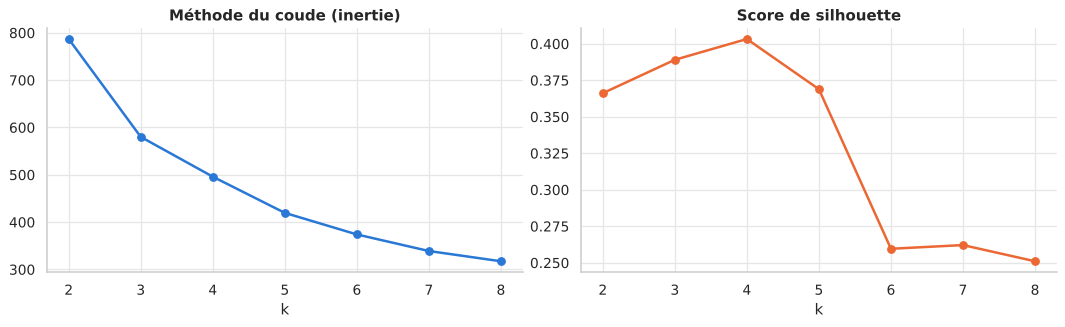

k retenu (silhouette max) : 4 → silhouette = 0.403


In [44]:
Xc = StandardScaler().fit_transform(feat)
ks, sils, inertias = range(2, 9), [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(Xc)
    sils.append(silhouette_score(Xc, km.labels_)); inertias.append(km.inertia_)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(list(ks), inertias, marker="o", color=PALETTE[0]); axes[0].set_title("Méthode du coude (inertie)")
axes[1].plot(list(ks), sils, marker="o", color=PALETTE[1]); axes[1].set_title("Score de silhouette")
for a in axes: a.set_xlabel("k")
plt.tight_layout(); plt.show()
K = list(ks)[int(np.argmax(sils))]
print("k retenu (silhouette max) :", K, "→ silhouette =", round(max(sils), 3))

Pas de coude clair, silhouette max à k = 4 (≈ 0,40).

In [45]:
km = KMeans(n_clusters=K, n_init=50, random_state=RANDOM_STATE).fit(Xc)
# cluster 0 = le plus grand
order_ = pd.Series(km.labels_).value_counts().index
feat["cluster"] = pd.Series(km.labels_).map({old: new for new, old in enumerate(order_)}).values
prof = feat.groupby("cluster").mean().round(2)
prof.insert(0, "n_partenaires", feat.cluster.value_counts().sort_index())
for c_ in prof.index[prof.n_partenaires <= 12]:
    print(f"Cluster {c_} :", ", ".join(f"{p} {names[p]} ({roles[p]})" for p in feat.index[feat.cluster == c_]))
prof

Cluster 1 : BP-30004 Common Ground Climate Forum (service_partner), BP-30006 Avelora Food Standards Office (customer), BP-30010 Tembara Coastal Administration (customer), BP-30027 Kintara Emergency Response Office (customer), BP-30036 Office of the Kintara Chancellor (customer), BP-30051 Tembara Customs Coordination Unit (customer), BP-30061 Kintara Rural Transport Board (customer), BP-30063 Nordhaven Maritime Safety Agency (customer), BP-30067 Avelora Ministry of Strategic Resources (customer), BP-30071 Valenne Public Procurement Authority (customer), BP-30076 Avelora Council of State (customer)
Cluster 2 : BP-30005 Warden Medical Ventures (service_partner), BP-30013 Vann Maritime Advisory (service_partner), BP-30022 Varlan Natural History Circle (customer), BP-30026 Valenne Industrial Supply Consortium (customer), BP-30034 Commonway Legal Registry Services (service_partner), BP-30038 Vosmere Biotechnics (supplier_customer), BP-30048 Cedar Public Affairs Advisory (service_partner), BP

,n_partenaires,n_po_supplier,po_amount_log,po_price_ratio_med,po_rule_rate,n_sent,n_received,n_carried,sh_problem_rate,sh_anomaly_rate,sh_rule_rate,sh_restricted_emergency_rate,sh_bio_rate,n_categories
cluster,,,,,,,,,,,,,,
0,57,2.03,12.06,1.00,0.15,1.69,1.63,0.55,0.11,0.06,0.14,0.21,0.05,2.06
1,11,0.00,0.00,0.00,0.00,1.67,1.79,0.00,0.11,0.05,0.15,0.13,0.07,2.13
2,9,2.12,12.16,1.00,0.93,0.08,0.12,0.00,0.00,0.00,0.00,0.00,0.00,0.12
3,3,3.51,13.93,1.01,0.09,3.23,3.72,1.25,0.10,0.04,0.47,0.23,0.29,2.78


- Cluster 0 (57) : partenaires « normaux », commandes et expéditions.
- Cluster 1 (11) : clients, reçoivent et envoient mais ne vendent rien.
- Cluster 2 (9) : fournisseurs sans expédition, 93 % de leurs commandes violent une règle. On y trouve les 8 inactifs et BP-30048 (commandé avant référencement).
- Cluster 3 (3) : les hubs (Meridian, Asterion, Horizon Field Research). Gros volumes, 29 % d'échantillons biologiques, 47 % d'expéditions avec une règle violée.

partner_role,carrier,customer,service_partner,supplier,supplier_customer
cluster,,,,,
0,8,17,13,14,5
1,0,10,1,0,0
2,0,3,5,0,1
3,1,2,0,0,0


risk_class,low,standard,review,elevated
cluster,,,,
0,9,24,15,9
1,4,4,3,0
2,2,7,0,0
3,0,2,1,0


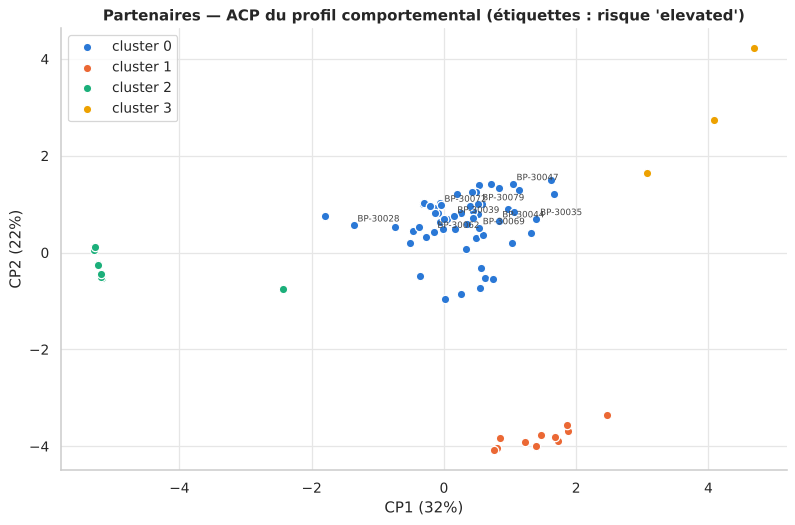

In [46]:
bp_full = clean["erp_business_partners"].set_index("partner_code").join(feat.cluster)
display(pd.crosstab(bp_full.cluster, bp_full.partner_role))
display(pd.crosstab(bp_full.cluster, bp_full.risk_class)[["low", "standard", "review", "elevated"]])
pc = PCA(n_components=2).fit(Xc); Pp = pc.transform(Xc)
fig, ax = plt.subplots(figsize=(9, 6))
for c in range(K):
    m = feat.cluster.values == c
    ax.scatter(Pp[m, 0], Pp[m, 1], s=45, color=PALETTE[c], edgecolor="white", label=f"cluster {c}")
for i, code_ in enumerate(feat.index):
    if bp_full.loc[code_, "risk_class"] == "elevated":
        ax.annotate(code_, (Pp[i, 0], Pp[i, 1]), fontsize=7, color="#444", xytext=(3, 3), textcoords="offset points")
ax.set_title("Partenaires — ACP du profil comportemental (étiquettes : risque 'elevated')"); ax.legend()
ax.set_xlabel(f"CP1 ({pc.explained_variance_ratio_[0]:.0%})"); ax.set_ylabel(f"CP2 ({pc.explained_variance_ratio_[1]:.0%})")
plt.tight_layout(); plt.show()

Aucun des 9 partenaires `elevated` n'est dans les clusters 2 ou 3, et les hubs sont `standard` ou `review`. La `risk_class` ne correspond pas au comportement observé.

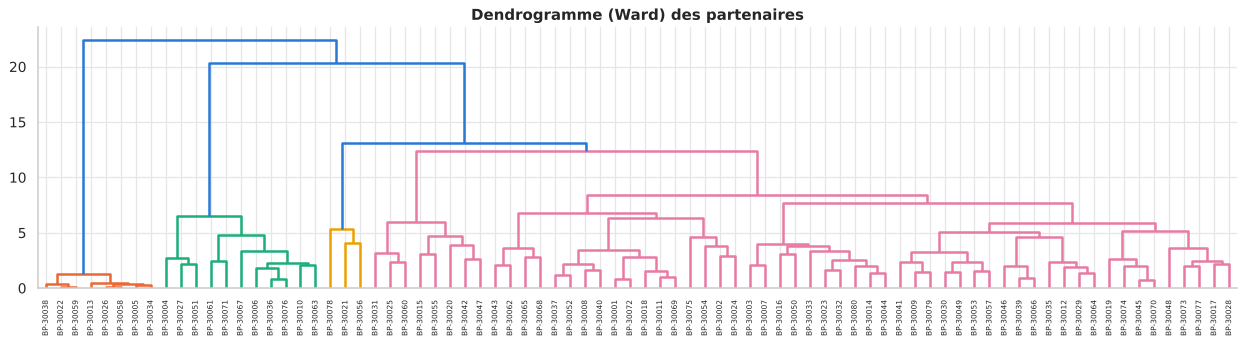

Accord K-Means / CAH (Adjusted Rand Index) : 0.959


In [47]:
# CAH (Ward) pour comparer avec K-Means
Zl = linkage(Xc, method="ward")
plt.figure(figsize=(14, 4))
dendrogram(Zl, labels=feat.index.tolist(), leaf_font_size=6, color_threshold=Zl[-K + 1, 2])
plt.title("Dendrogramme (Ward) des partenaires"); plt.tight_layout(); plt.show()
hc = fcluster(Zl, K, criterion="maxclust")
from sklearn.metrics import adjusted_rand_score
print("Accord K-Means / CAH (Adjusted Rand Index) :", round(adjusted_rand_score(km.labels_, hc), 3))

ARI ≈ 0,96 entre K-Means et CAH : les clusters sont stables. Les hubs se séparent très haut dans le dendrogramme.

## 9. Règles d'association (Apriori)

On cherche les combinaisons d'attributs qui vont ensemble (support, confiance, lift). Apriori est codé à la main pour ne pas dépendre de `mlxtend`.

In [48]:
ATTRS = ["item_category", "temperature_control_class", "authorization_class", "declared_purpose",
         "shipment_status", "origin_category", "destination_category", "same_region"]
tx = sh[ATTRS].astype(str).apply(lambda col: col.name + "=" + col)
onehot = pd.get_dummies(tx.stack()).groupby(level=0).max().astype(bool)

def apriori(df, min_support=0.03, max_len=3):
    n = len(df); freq = {}
    current = [frozenset([c]) for c in df.columns if df[c].mean() >= min_support]
    for c in current: freq[c] = df[list(c)[0]].mean()
    k = 1
    while current and k < max_len:
        k += 1
        items = sorted(set().union(*current))
        cands = {a | frozenset([i]) for a in current for i in items if i not in a}
        # deux items du même attribut ne peuvent pas coexister
        cands = [c for c in cands if len({x.split("=")[0] for x in c}) == len(c)]
        current = []
        for c in cands:
            if all(frozenset(s) in freq for s in combinations(c, k - 1)):
                sup = df[list(c)].all(axis=1).mean()
                if sup >= min_support: freq[c] = sup; current.append(c)
    return freq

def rules_from(freq, min_conf=0.5):
    out = []
    for iset, sup in freq.items():
        if len(iset) < 2: continue
        for r in range(1, len(iset)):
            for ante in map(frozenset, combinations(iset, r)):
                cons = iset - ante
                conf = sup / freq[ante]
                if conf >= min_conf:
                    out.append((", ".join(sorted(ante)), ", ".join(sorted(cons)), sup, conf, conf / freq[cons]))
    return pd.DataFrame(out, columns=["si", "alors", "support", "confiance", "lift"])

freq = apriori(onehot, min_support=0.03, max_len=3)
rules = rules_from(freq, min_conf=0.6)
print(len(freq), "itemsets fréquents,", len(rules), "règles (confiance ≥ 0,6)")
rules.sort_values(["lift", "confiance"], ascending=False).head(15).round(3)

619 itemsets fréquents, 773 règles (confiance ≥ 0,6)


,si,alors,support,confiance,lift
672,declared_purpose=environmental and wildlife reference materials,"item_category=biological_sample, same_region=True",0.040,1.000,16.667
675,"item_category=biological_sample, same_region=True",declared_purpose=environmental and wildlife reference materials,0.040,0.667,16.667
257,declared_purpose=temperature-controlled clinical programme delivery,"origin_category=office, temperature_control_class=2-8C",0.058,1.000,10.714
259,"origin_category=office, temperature_control_class=2-8C",declared_purpose=temperature-controlled clinical programme delivery,0.058,0.619,10.714
446,declared_purpose=environmental and wildlife reference materials,"same_region=True, temperature_control_class=2-8C",0.040,1.000,10.465
309,declared_purpose=environmental and wildlife reference materials,"item_category=biological_sample, shipment_status=delivered",0.040,1.000,8.824
133,declared_purpose=environmental and wildlife reference materials,item_category=biological_sample,0.040,1.000,8.654
310,"declared_purpose=environmental and wildlife reference materials, shipment_status=delivered",item_category=biological_sample,0.040,1.000,8.654
627,declared_purpose=environmental and wildlife reference materials,"item_category=biological_sample, temperature_control_class=2-8C",0.040,1.000,8.654
629,"declared_purpose=environmental and wildlife reference materials, temperature_control_class=2-8C",item_category=biological_sample,0.040,1.000,8.654


- « environmental and wildlife reference materials » ⇒ échantillons biologiques, 2-8 °C, même région (lift 16,7). 11 de ces 18 cas sont les envois vers soi-même du §6.2.
- « temperature-controlled clinical programme delivery » ⇒ départ d'un bureau en 2-8 °C (confiance 100 %, lift 10,7). Les envois froids depuis le siège sont systématiques pour ce motif, ce qui fait penser à une erreur de paramétrage.
- Les flux 2-8 °C liés aux hubs sont à 67–81 % des échantillons biologiques.

In [49]:
# règles menant à delayed/returned (support plus bas, problèmes rares)
freq_low = apriori(onehot, min_support=0.01, max_len=3)
r_low = rules_from(freq_low, min_conf=0.2)
r_prob = r_low[r_low.alors.str.contains("shipment_status=(delayed|returned)")].sort_values("lift", ascending=False)
r_prob.head(10).round(3)

,si,alors,support,confiance,lift
2009,"item_category=monitoring_equipment, same_region=False",shipment_status=delayed,0.018,0.235,3.114
105,item_category=monitoring_equipment,shipment_status=delayed,0.020,0.214,2.836
3373,item_category=monitoring_equipment,"shipment_status=delayed, temperature_control_class=ambient",0.020,0.214,2.836
3376,"item_category=monitoring_equipment, temperature_control_class=ambient",shipment_status=delayed,0.020,0.214,2.836
2012,"origin_category=field_depot, temperature_control_class=ambient",shipment_status=delayed,0.011,0.200,2.647


Confiances faibles (≤ 24 %). Le meilleur cas, `monitoring_equipment` hors région, est retardé 1 fois sur 4 (lift 3,1). Rien ne prédit vraiment un problème.

## 10. Classification des expéditions à problème

Cible : statut `delayed` ou `returned`. On exclut les `in_transit` et la durée de transit (connue seulement à l'arrivée). Classes déséquilibrées : CV stratifiée à 5 plis, `class_weight="balanced"` et ROC-AUC.

In [50]:
d = X_sh[sh.shipment_status != "in_transit"].copy()
y = d.shipment_status.isin(["delayed", "returned"]).astype(int)
print("Taille :", len(d), "| taux de problèmes :", y.mean().round(3))
num_c = ["log_qty", "hour", "weekday", "year"]
cat_c = cat_sh + ["same_region", "carrier_partner_code"]
d["same_region"] = d.same_region.astype(str)
prep = ColumnTransformer([("num", StandardScaler(), num_c),
                          ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_c)])
models = {
    "Régression logistique": LogisticRegression(max_iter=2000, class_weight="balanced", C=0.5),
    "Arbre de décision (prof. 4)": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=3, class_weight="balanced", random_state=RANDOM_STATE),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
res, probas = [], {}
for name, m in models.items():
    pipe = Pipeline([("prep", prep), ("model", m)])
    p = cross_val_predict(pipe, d[num_c + cat_c], y, cv=cv, method="predict_proba")[:, 1]
    probas[name] = p
    pred = (p >= 0.5).astype(int)
    tp = ((pred == 1) & (y == 1)).sum()
    res.append((name, roc_auc_score(y, p), tp / max(pred.sum(), 1), tp / y.sum()))
pd.DataFrame(res, columns=["modèle", "ROC-AUC", "précision (classe problème)", "rappel (classe problème)"]).round(3)

Taille : 433 | taux de problèmes : 0.111


,modèle,ROC-AUC,précision (classe problème),rappel (classe problème)
0,Régression logistique,0.535,0.118,0.312
1,Arbre de décision (prof. 4),0.567,0.130,0.708
2,Random Forest,0.565,0.100,0.146


ROC-AUC entre 0,53 et 0,57, à peine mieux que le hasard. L'arbre a un rappel de ~70 % mais une précision de 13 % (taux de base 11 %). Les infos connues au départ ne suffisent pas à prédire les retards et retours.

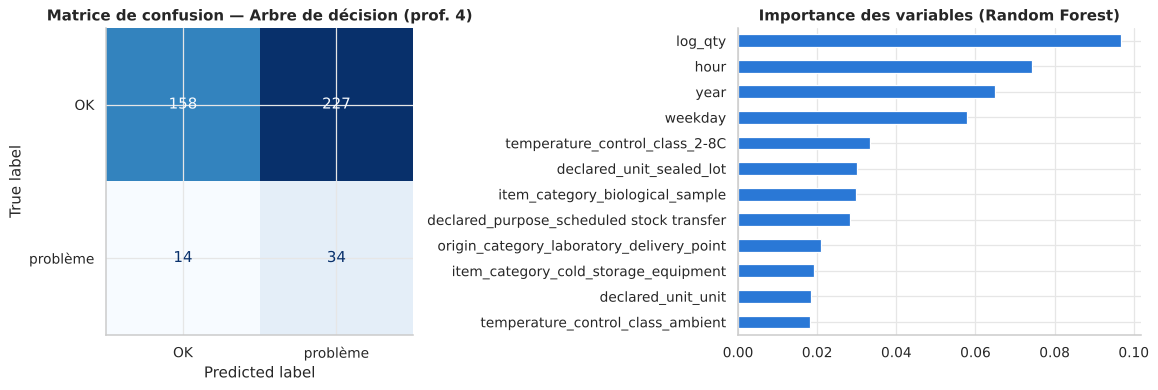

In [51]:
best = max(probas, key=lambda k: roc_auc_score(y, probas[k]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y, probas[best] >= 0.5), display_labels=["OK", "problème"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Matrice de confusion — {best}")
rf = Pipeline([("prep", prep), ("model", models["Random Forest"])]).fit(d[num_c + cat_c], y)
names_ = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names_).sort_values().tail(12)
imp.index = imp.index.str.replace("num__|cat__", "", regex=True)
imp.plot.barh(ax=axes[1], color=PALETTE[0]); axes[1].set_title("Importance des variables (Random Forest)")
plt.tight_layout(); plt.show()

L'arbre signale ~260 expéditions pour en attraper ~34. Dans la forêt, les variables les plus importantes sont continues (quantité, heure, année, jour), biais connu de l'importance par impureté.

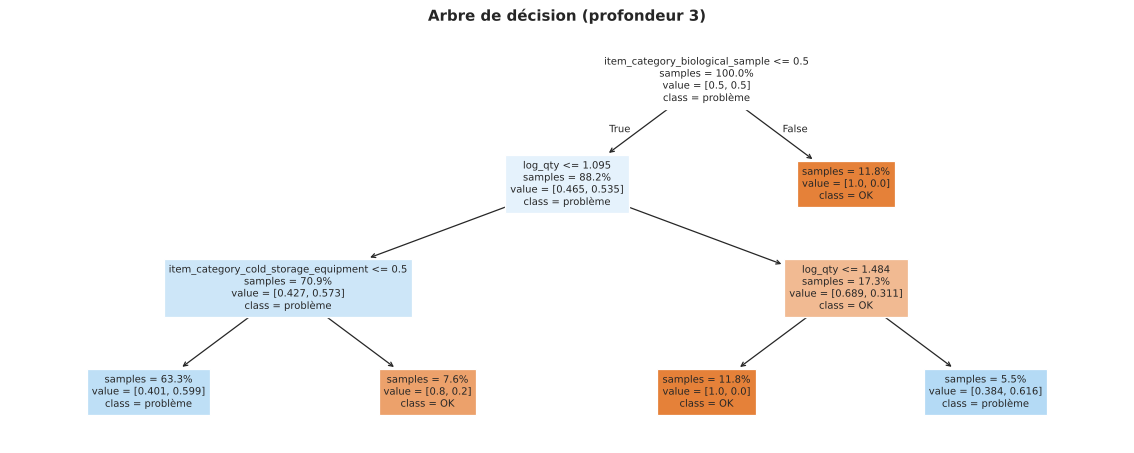

In [52]:
# arbre de profondeur 3 pour la lisibilité
tree = Pipeline([("prep", prep), ("model", DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=RANDOM_STATE))]).fit(d[num_c + cat_c], y)
plt.figure(figsize=(16, 6))
plot_tree(tree.named_steps["model"], feature_names=[n.replace("num__", "").replace("cat__", "") for n in names_],
          class_names=["OK", "problème"], filled=True, impurity=False, proportion=True, fontsize=8)
plt.title("Arbre de décision (profondeur 3)"); plt.show()

Premier critère : échantillon biologique. Aucune expédition biologique terminée n'a eu de problème. Les autres feuilles restent proches de 50/50.

## 11. Analyse temporelle

Agrégation par année (trop peu de données par mois).

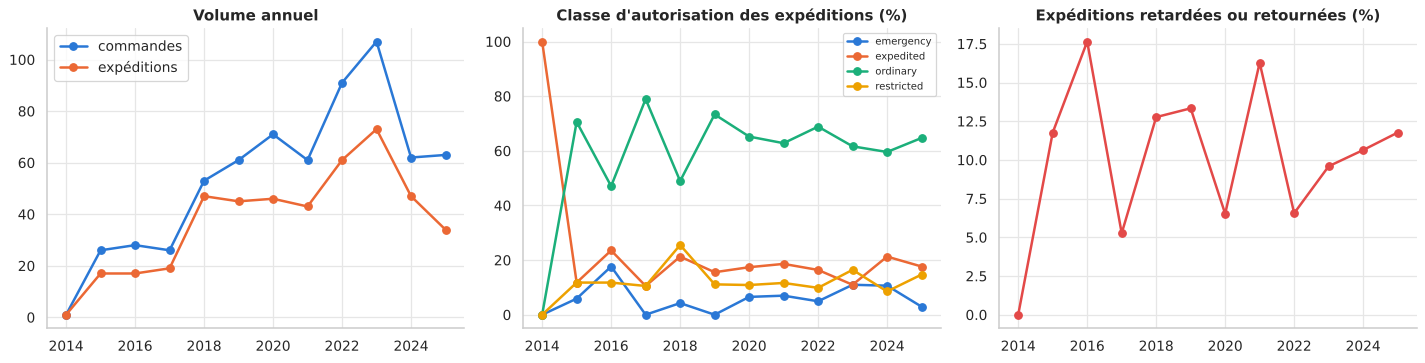

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
po_gr.groupby("year").size().plot(ax=axes[0], marker="o", label="commandes", color=PALETTE[0])
sh.groupby("year").size().plot(ax=axes[0], marker="o", label="expéditions", color=PALETTE[1])
axes[0].set_title("Volume annuel"); axes[0].legend()
(pd.crosstab(sh.year, sh.authorization_class, normalize="index") * 100).plot(ax=axes[1], marker="o", color=PALETTE[:4])
axes[1].set_title("Classe d'autorisation des expéditions (%)"); axes[1].legend(fontsize=8)
(sh.assign(pb=sh.shipment_status.isin(["delayed", "returned"])).groupby("year").pb.mean() * 100).plot(ax=axes[2], marker="o", color=PALETTE[7])
axes[2].set_title("Expéditions retardées ou retournées (%)")
for a in axes: a.set_xlabel("")
plt.tight_layout(); plt.show()

- Activité en hausse jusqu'à un pic en 2023 (107 commandes, 73 expéditions), puis baisse. 2025 est sûrement incomplète.
- Autorisations `emergency` : 0–7 % entre 2017 et 2022, ~11 % en 2023–2024.
- Taux de retards/retours entre 5 et 18 %, sans tendance.

In [54]:
# envois bio par année et motif
bio = sh[sh.item_category == "biological_sample"]
pd.crosstab(bio.year, bio.declared_purpose)

declared_purpose,agricultural distribution,customer distribution,environmental and wildlife reference materials,facility replenishment,field programme support,laboratory delivery,scheduled stock transfer,temperature-controlled clinical programme delivery
year,,,,,,,,
2014,0,0,0,0,0,0,0,1
2015,0,1,0,0,0,1,2,0
2016,0,0,0,1,0,0,0,1
2017,0,0,0,0,0,0,0,3
2018,0,0,3,0,1,0,0,1
2019,0,0,3,1,1,0,0,1
2020,1,0,2,1,1,1,0,1
2021,0,0,2,0,0,0,0,2
2022,0,0,1,0,0,0,1,1


Depuis 2018, le motif principal des envois d'échantillons biologiques est « environmental and wildlife reference materials » (2 à 3 par an). Sur 18 envois, 11 vont d'un hub Meridian vers lui-même (FCL-1019, 1020) et 7 vont de FCL-1030 (dépôt sans froid) vers FCL-1024. Les disparitions de stock dans ces hubs commencent aussi en 2018.

## 12. Score de risque et export

Score additif par transaction : règles violées ×2, Isolation Forest ×2, LOF ×1, partenaire `elevated` ×1. Puis agrégation par site.

In [55]:
sh["risk_score"] = sh.n_rule_flags * 2 + sh.iso_flag.astype(int) * 2 + sh.lof_flag.astype(int) + rules_sh["partenaire à risque élevé"].astype(int)
po_gr["risk_score"] = po_gr.n_rule_flags * 2 + po_gr.iso_flag.astype(int) * 2
top_sh = sh.sort_values(["risk_score", "iso_score"], ascending=False)
top_sh[["shipment_number", "dispatch_time", "item_category", "temperature_control_class", "origin_facility_code",
        "destination_facility_code", "declared_purpose", "authorization_class", "shipment_status", "n_rule_flags",
        "iso_flag", "lof_flag", "risk_score"]].head(15)

,shipment_number,dispatch_time,item_category,temperature_control_class,origin_facility_code,destination_facility_code,declared_purpose,authorization_class,shipment_status,n_rule_flags,iso_flag,lof_flag,risk_score
100,SHP-2018-00047,2018-12-29 11:00:00,agricultural_product,frozen,FCL-1011,FCL-1011,customer distribution,expedited,delivered,3,True,False,8
27,SHP-2016-00010,2016-09-12 17:00:00,medical_consumables,2-8C,FCL-1011,FCL-1011,scheduled stock transfer,restricted,returned,3,False,True,7
356,SHP-2023-00061,2023-09-15 11:00:00,agricultural_product,frozen,FCL-1006,FCL-1029,agricultural distribution,ordinary,delivered,2,True,False,6
343,SHP-2023-00048,2023-09-06 13:00:00,medical_consumables,2-8C,FCL-1017,FCL-1013,customer distribution,restricted,delivered,2,True,False,6
303,SHP-2023-00008,2023-04-03 18:00:00,biological_sample,2-8C,FCL-1011,FCL-1019,customer distribution,emergency,delivered,1,True,True,5
34,SHP-2016-00017,2016-12-20 08:00:00,biological_sample,2-8C,FCL-1002,FCL-1028,facility replenishment,emergency,delivered,1,True,True,5
3,SHP-2015-00003,2015-02-17 15:00:00,biological_sample,2-8C,FCL-1019,FCL-1011,laboratory delivery,restricted,delivered,1,True,True,5
192,SHP-2021-00001,2021-01-12 14:00:00,medical_consumables,2-8C,FCL-1030,FCL-1027,field programme support,expedited,delivered,2,False,True,5
440,SHP-2025-00025,2025-05-17 12:00:00,biological_sample,2-8C,FCL-1013,FCL-1030,field programme support,ordinary,delivered,2,False,True,5
390,SHP-2024-00022,2024-06-05 17:00:00,biological_sample,2-8C,FCL-1029,FCL-1006,agricultural distribution,ordinary,delivered,2,False,False,5


En tête : SHP-2018-00047 (surgelé, du siège vers lui-même, atypique pour IF) et SHP-2016-00010 (consommables 2-8 °C, du siège vers lui-même, `restricted`, retournée).

In [56]:
# agrégation par site
n_ship = sh.origin_facility_code.value_counts().add(sh.destination_facility_code.value_counts(), fill_value=0)
site_risk = pd.DataFrame({
    "nb_expéditions": n_ship,
    "score_expéditions (origine+dest.)": sh.groupby("origin_facility_code").risk_score.sum().add(sh.groupby("destination_facility_code").risk_score.sum(), fill_value=0),
    "score_commandes": po_gr.groupby("ordering_facility_code").risk_score.sum(),
    "disparitions_stock_significatives": inv[inv.shortfall].groupby("facility_code").size(),
    "ajustements_non_justifiés": adj[~adj.justified].groupby("facility_code").size(),
    "ajustements_pièce_incohérente": adj[adj["pièce_incohérente"]].groupby("facility_code").size(),
}).fillna(0)
site_risk.insert(0, "site", fac.facility_name.reindex(site_risk.index))
site_risk["score_moyen_par_expédition"] = site_risk["score_expéditions (origine+dest.)"] / site_risk.nb_expéditions
site_risk.sort_values("score_expéditions (origine+dest.)", ascending=False).head(12).round(2)

,site,nb_expéditions,score_expéditions (origine+dest.),score_commandes,disparitions_stock_significatives,ajustements_non_justifiés,ajustements_pièce_incohérente,score_moyen_par_expédition
FCL-1011,Meridian Valenne Headquarters,150.0,151,84,0.0,1.0,1.0,1.01
FCL-1019,Meridian Avelora Transfer Annex,87.0,70,30,5.0,3.0,2.0,0.8
FCL-1030,Kintara Cave Authority Field Depot,52.0,63,34,0.0,2.0,0.0,1.21
FCL-1010,Asterion Central Clinical Campus,91.0,62,58,5.0,18.0,2.0,0.68
FCL-1007,Asterion Avelora Executive Clinic,75.0,55,46,0.0,17.0,0.0,0.73
FCL-1029,Vale Strategy Valenne Office,44.0,51,18,0.0,1.0,3.0,1.16
FCL-1020,Meridian Tembara Coastal Hub,51.0,36,18,6.0,2.0,0.0,0.71
FCL-1016,Northstar Tembara Cold-Chain Hub,44.0,35,16,0.0,1.0,1.0,0.8
FCL-1013,Nordhaven Refrigeration Workshop,17.0,28,4,0.0,0.0,0.0,1.65
FCL-1015,Threshold Earth Avelora Laboratory,30.0,24,12,0.0,2.0,0.0,0.8


- FCL-1011 (siège) : score le plus élevé mais surtout à cause du volume (150 expéditions). Score moyen ≈ 1, lié aux envois froids depuis un bureau.
- FCL-1019 / 1020 (et 1024, 1027) : disparitions d'échantillons, envois vers soi-même, ajustements mal justifiés. C'est le cas le plus inquiétant.
- FCL-1010 / 1007 : 35 ajustements sans pièce à eux deux, disparitions de consommables à FCL-1010.

FCL-1006 et FCL-1013 ont peu d'expéditions mais un score moyen élevé.

In [57]:
for name, df in clean.items():
    df.to_csv(OUT_DIR / f"{name}_clean.csv", index=False)
po_gr.to_csv(OUT_DIR / "po_receipts_enriched.csv", index=False)
sh.to_csv(OUT_DIR / "shipments_enriched.csv", index=False)
inv.to_csv(OUT_DIR / "inventory_balance_check.csv", index=False)
feat.to_csv(OUT_DIR / "partner_clusters.csv")
rules.sort_values("lift", ascending=False).to_csv(OUT_DIR / "association_rules.csv", index=False)
print("Fichiers exportés :", sorted(p.name for p in OUT_DIR.glob("*.csv")))

Fichiers exportés : ['association_rules.csv', 'erp_business_partners_clean.csv', 'erp_facilities_clean.csv', 'goods_receipts_clean.csv', 'inventory_adjustments_clean.csv', 'inventory_balance_check.csv', 'inventory_month_end_clean.csv', 'partner_clusters.csv', 'po_receipts_enriched.csv', 'purchase_order_lines_clean.csv', 'shipments_clean.csv', 'shipments_enriched.csv']


Fichiers exportés dans `data/logistics/outputs/`.

## Conclusions

**Qualité des données.** Pas de clé orpheline, mais des défauts de saisie : doublons, 4 formats de date, virgules décimales, unités collées, casse, régions à deux niveaux, et coordonnées GPS fausses (distances inutilisables).

**Constats principaux :**
1. Disparitions d'échantillons biologiques dans les hubs Meridian (FCL-1019, 1020, 1027, 1024), la plupart sans ajustement.
2. Dans ces mêmes hubs, des envois d'échantillons biologiques vers le site lui-même depuis 2018.
3. Ajustements mal justifiés : pièce d'un autre site ou postérieure, et 61 % sans pièce.
4. Chaîne du froid : 71 envois froids depuis un site sans froid (surtout le siège), 29 vers un site non équipé. Sûrement du paramétrage.
5. Achats : 10 commandes avant référencement, 69 à des fournisseurs inactifs, 62 sous-livraisons acceptées.

**Méthodes.** Les règles métier et les contrôles entre tables donnent les résultats les plus solides. Le clustering retrouve les fournisseurs problématiques et les hubs, et montre que `risk_class` ne reflète pas l'activité. Les règles d'association montrent que certains écarts sont systématiques. La détection d'anomalies marche surtout sur les commandes (74 % de recouvrement avec les règles). La classification ne marche pas (AUC ≈ 0,55).

**Limites.** Pas d'historique des statuts partenaires, stocks sur 5 sites et 20 mois seulement, seuils choisis à la main (5 %, |z| > 3, contamination 5 %), petits effectifs. Les résultats d'IF, K-Means et RF peuvent un peu varier selon la version de scikit-learn.

**Pistes.** Croiser les envois vers soi-même avec les mouvements de stock mois par mois, récupérer l'historique des statuts, corriger les coordonnées, faire valider les cas prioritaires par le métier.